# Ceridwen photometry and spectroscopy fit

- Joint fit of COSMOS2015 photometry and the LEGA-C DR2 spectrum of one galaxy.

## Settings and priors

- The batch launcher sets target, manifest index, seed and result directory per galaxy.
- Every fit setting and prior is in the two dicts below; nothing else is configurable.
- String prior entries are resolved from the grid and the catalogue in the model cell.
- A parameter is sampled only when it has a `PRIORS` entry.
- Noll slope and bump amplitude have independent priors.

In [1]:
import os
import sys
import threading
from itertools import pairwise
from pathlib import Path

os.environ["JAX_ENABLE_X64"] = "1"

import astropy.units as u
from astropy.constants import c as C_LIGHT
import corner
import h5py
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.table import Table
from astropy.visualization import AsinhStretch, ImageNormalize, PercentileInterval
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from ceridwen import Cosmology
from ceridwen.broadening import Instrument, Kinematics
from ceridwen.cosmology import age_gyr, flux_factor_cgs
from ceridwen.csp import CSPBasis_afe
from ceridwen.fit import load_result_h5
from ceridwen.likelihood import (
    DiagonalGaussianLikelihood,
    DiagonalNoiseModel,
    MultiObservationLikelihood,
    EmissionLineColumns,
    PolynomialCalibration,
)
from ceridwen.likelihood.emission_lines import read_fsps_line_list
from ceridwen.model import SedModel, logsfr_ratios_to_sfh, mass_mapped_beta, mass_mapped_zh
from ceridwen.observation import Photometry, Spectrum
from ceridwen.observation.absorption_features import absorption_feature_mask
from ceridwen.sampler import run_sampler
from ceridwen.sampler.nested import BlackJAXNestedSamplerAdapter
from ceridwen.sampler.priors import ClippedNormal, StudentT, Uniform
from ceridwen.ssps import SSPDataAfe, fetch_grid
from ceridwen.ssps.abundance_response import AlfCNResponse
from scipy.special import softmax
from scipy.stats import entropy
from specutils.utils.wcs_utils import air_to_vac

jax.config.update("jax_enable_x64", True)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from cosmos_photometry import fit_photometry, resolve_photometry  # noqa: E402
from per_galaxy_diagnostics import model_parameter_block  # noqa: E402
from spectral_figures import (  # noqa: E402
    mark_absorption_features,
    mark_rest_wavelength_axis,
    plot_photometry_fit,
    set_plain_log_ticks,
    spectral_tight_layout,
)

TARGET_ID = "M12_185631"
MANIFEST_INDEX = 2574
SEED = 20260832
RESULT_DIR = PROJECT_ROOT / "results/legac-dr3-2026-11-11/window-194/run/fits/dr3_plain_w/185631-M12_185631"
QUICK = False

# '0' on the GPU box: figures render nothing under Agg and are rebuilt locally
# by scripts/regenerate_fit_notebooks.py, so skip their construction there.
PLOTS = os.environ.get("CERIDWEN_PLOTS", "1") == "1"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

SETTINGS = {
    "photometry": "cosmos2020_classic",  # default since 23 Sep 2026; outside its footprint resolve to cosmos2020_classic
    "data_source": "legac_dr2",  # "legac_dr3": DR3 catalogue and spectra (data/raw/legac_dr3); "manga_dr17": MaNGA cube summed in the NSA Petrosian aperture, NSA FNugriz + WISE W1, W2
    "mock_data": None,  # generated NPZ on the selected target wavelength/filter grids
    "abundance_response": None,  # optional path to pinned alf Kroupa response files; C/N offsets, default off
    "fix_afe": None,  # None: sample afe; float (e.g. 0.0): fix afe for the solar-scaled comparison
    "ssp_grid": "~/.ceridwen/grids/amist_c3k_hr_krou_afe_nebular.h5",  # registry key or local .h5 path; this grid: scripts/build_nebular_grid.py; single-plane grids fix afe
    # "cosmos_total": Laigle+16 aperture-to-total, extinction and zero-point corrections (stored fits)
    "photometry_floor": 0.05,  # fractional error floor added in quadrature
    "emission_lines": [3934.77, 3966.6, 3973.3, 4227.92],  # rest vacuum A, masked +/- 1500 km/s: Ca II K, Ca II H (two entries clear of H-epsilon), Ca I
    "emission_line_marginalisation": True,  # True: FSPS lines get free fluxes >= 0 in the calibration solve, shared with the photometry; z fixed; lines leave the mask
    "telluric_air": (7590.0, 7660.0),  # observed A, masked
    "sky_lines_air": [],  # observed air A ranges, masked; e.g. [(5572.0, 5583.0)]: [O I] 5577.339 sky line (NIST ASD)
    "rest_range": None,  # rest vacuum A (low, high): spectrum pixels outside leave the fit; None: all
    "photometry_excluded": [],  # band labels left out of the fit, e.g. ["W1", "W2"]; every band: spectrum only
    "spectrum_floor_anchor": "model",  # fractional floor f_calib * |mu| on the uncalibrated model ("model") or f_calib * |y| on the data ("data")
    "masked_absorption_features": [],  # Lick feature bandpasses masked (Trager+98 Table 2), e.g. ["CN4150", "G4300", "Fe4383", "C4668"]
    "sfh_nbins": 14,  # Prospector continuity bins: 0-30 and 30-100 Myr, log-spaced, last bin 0.85 * t_univ to t_univ
    "calibration_order": 10,  # Chebyshev polynomial on the model spectrum, marginalised analytically
    "calibration_prior_sigma": 0.1,  # shape coefficients a_1 through a_10
    "calibration_constant_prior_sigma": 0.3,  # constant coefficient a_0
    "calibration_fit_constant": True,  # a_0 handles spectrum normalisation; its width is set separately
    "zred_half_width": 0.1,  # zred prior: catalogue z +/- this
    "sigma_clip": 3.0,  # sigma_smooth prior: DR2 sigma +/- this many DR2 errors
    "birth_cloud_dust": True,  # True: power-law optical depth dust_ratio * diffuse_tau_noll, index -1, on stars younger than 10 Myr (FSPS dust1)
    "metallicity_evolution": True,  # True: Z rises with formed mass, Gallazzi+26 Table 1; Z is then log10 of the formed-mass-weighted metallicity
    "sampler": {"num_live": 500, "num_inner_steps": 65, "num_delete": 100, "logZ_tol": -5.0},
    "sampler_quick": {"num_live": 16, "num_inner_steps": 2, "num_delete": 8, "logZ_tol": 1e4},
}
PRIORS = {
    "logmass": Uniform(low=8.0, high=13.0),
    "logsfr_ratios": StudentT(mean=0.0, scale=0.3, df=2.0),  # log10 SFR ratio of adjacent bins
    "logzsol": "Uniform over the grid",  # log10(Z/Z_sun), Z_sun = 0.0185; equals [Fe/H] on this grid
    "zh_beta_unit": Uniform(low=0.0, high=1.0),  # sampled only with metallicity_evolution; beta = 1/(1+alpha) from 0.05 to min(0.80, logzsol_f on the grid)
    "afe": "Uniform over the grid",
    "cfe": Uniform(low=-0.3, high=0.5),  # alf C offset [dex], sampled only with abundance_response
    "nfe": Uniform(low=-0.3, high=1.0),  # alf N offset [dex], sampled only with abundance_response
    "diffuse_tau_noll": Uniform(low=0, high=1),
    "diffuse_delta": Uniform(low=-1.0, high=0.4),  # Noll slope
    "diffuse_Ebump": Uniform(low=0.0, high=6.0),  # independent Drude amplitude E_b
    "dust_ratio": ClippedNormal(mean=1.0, sigma=0.3, low=0.0, high=2.0),  # birth-cloud / diffuse optical depth; sampled only with birth_cloud_dust
    "log_f_calib": Uniform(low=np.log(0.01), high=np.log(0.10)),  # fractional noise floor on the spectrum
    "sigma_smooth": "ClippedNormal(sigma_DR2, err_DR2, clipped at sigma_clip err)",
}
C_KMS = float(C_LIGHT.to_value(u.km / u.s))
SETTINGS.update({'photometry': 'cosmos2025', 'data_source': 'legac_dr3', 'mock_data': None, 'abundance_response': None, 'fix_afe': None, 'ssp_grid': '/Users/liuhao/.ceridwen/grids/amist_c3k_hr_krou_afe_nebular.h5', 'photometry_floor': 0.05, 'emission_lines': [3934.77, 3966.6, 3973.3, 4227.92], 'emission_line_marginalisation': True, 'telluric_air': [7590.0, 7660.0], 'sky_lines_air': [], 'rest_range': [4074.5, 4666.1], 'photometry_excluded': [], 'spectrum_floor_anchor': 'model', 'masked_absorption_features': [], 'sfh_nbins': 14, 'calibration_order': 10, 'calibration_prior_sigma': 0.1, 'calibration_constant_prior_sigma': 0.3, 'calibration_fit_constant': True, 'zred_half_width': 0.1, 'sigma_clip': 3.0, 'birth_cloud_dust': True, 'metallicity_evolution': True, 'sampler': {'num_live': 500, 'num_inner_steps': 65, 'num_delete': 100, 'logZ_tol': -5.0}, 'sampler_quick': {'num_live': 16, 'num_inner_steps': 2, 'num_delete': 8, 'logZ_tol': 10000.0}})  # arm override

PRIORS['logmass'] = Uniform(low=8.0, high=13.0)  # arm override

PRIORS['logsfr_ratios'] = StudentT(mean=0.0, scale=0.3, df=2.0)  # arm override

PRIORS['logzsol'] = 'Uniform over the grid'  # arm override

PRIORS['zh_beta_unit'] = Uniform(low=0.0, high=1.0)  # arm override

PRIORS['afe'] = 'Uniform over the grid'  # arm override

PRIORS['cfe'] = Uniform(low=-0.3, high=0.5)  # arm override

PRIORS['nfe'] = Uniform(low=-0.3, high=1.0)  # arm override

PRIORS['diffuse_tau_noll'] = Uniform(low=0.0, high=1.0)  # arm override

PRIORS['diffuse_delta'] = Uniform(low=-1.0, high=0.4)  # arm override

PRIORS['diffuse_Ebump'] = Uniform(low=0.0, high=6.0)  # arm override

PRIORS['dust_ratio'] = ClippedNormal(mean=1.0, sigma=0.3, low=0.0, high=2.0)  # arm override

PRIORS['log_f_calib'] = Uniform(low=np.log(0.01), high=np.log(0.1))  # arm override

PRIORS['zred'] = 'Uniform(z_cat - zred_half_width, z_cat + zred_half_width)'  # arm override

PRIORS['sigma_smooth'] = 'ClippedNormal(sigma_DR2, err_DR2, clipped at sigma_clip err)'  # arm override


## Data and target

- Passive LEGA-C DR2 sample: quality flags, NUVrJ, weak [OII] and [OIII], clean twelve-band photometry.
- Target row, its public one-dimensional spectrum, catalogue redshift and dispersion.
- HST ACS F814W cutout with the COSMOS2015 3 arcsec aperture.
- `data_source` `legac_dr3`: DR3 catalogue row and spectrum, no DR2 selection.
- `data_source` `manga_dr17`: aperture spectrum, photometry, z and sigma from `scripts/manga_aperture_spectra.py`.

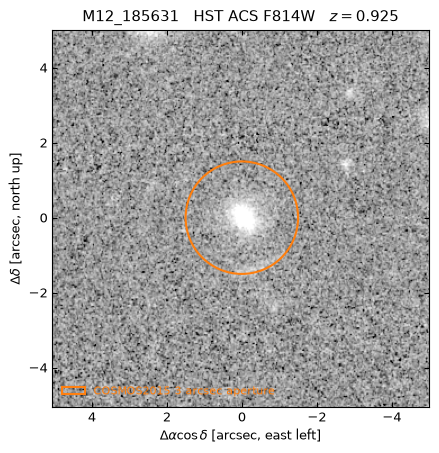

In [2]:
if SETTINGS["data_source"] == "manga_dr17":
    # Dereddened vacuum spectrum, LSFPOST sigma, NSA + WISE photometry, DAP z and V_rms
    manga_path = PROJECT_ROOT / "data/processed/manga_dr17" / f"{TARGET_ID}.fits"
    manga_header = fits.getheader(manga_path)
    manga_spectrum = Table.read(manga_path, "SPECTRUM")
    manga_photometry = Table.read(manga_path, "PHOTOMETRY")
    OBJECT_ID = int(manga_header["NSAID"])
    SURVEY_LABEL = "MaNGA"
    SPECTRUM_FLUX_UNIT = 1e-17 * u.erg / u.s / u.cm**2 / u.AA
    wave_vacuum = np.asarray(manga_spectrum["WAVE"], dtype=float)
    flux_native = np.asarray(manga_spectrum["FLUX"], dtype=float)
    error_native = np.asarray(manga_spectrum["ERROR"], dtype=float)
    good_pixel = np.asarray(manga_spectrum["VALID"], dtype=bool) & (error_native > 0)
    spectrum_instrument = Instrument.sigma_aa(np.asarray(manga_spectrum["LSF_SIGMA"], dtype=float), wave=wave_vacuum)
    z_catalog = float(manga_header["Z"])
    # Grid sigma_lib: 42 km/s below rest 9998.8 A, 143-255 km/s above (> MaNGA LSF); those pixels leave the fit
    good_pixel &= wave_vacuum / (1.0 + z_catalog) < 9998.0
    sigma_star = float(manga_header["SIGMA"])
    sigma_star_err = float(manga_header["SIGMAERR"])
    has_4000a_coverage = bool(
        wave_vacuum[good_pixel].min() < 4000 * (1 + z_catalog) < wave_vacuum[good_pixel].max()
    )
    catalogue_sn = float(np.median(flux_native[good_pixel] / error_native[good_pixel]))
else:
    if SETTINGS["data_source"] == "legac_dr3":
        # DR3, van der Wel et al. (2021): DR2 spectra re-reduced; Bagpipes flux calibration
        LEGAC_DIR = PROJECT_ROOT / "data/raw/legac_dr3"
        legac = Table.read(LEGAC_DIR / "legac_DR3.fits", hdu=1).to_pandas()
        legac = legac.rename(columns={"Z": "z", "SIGMA_STARS_PRIME_ERR": "SIGMA_STARS_PRIME_err"})
        for text_column in ["SPECT_ID", "Filename"]:
            legac[text_column] = legac[text_column].map(
                lambda value: (value.decode() if isinstance(value, bytes) else value).strip()
            )
        galaxy = legac[legac["SPECT_ID"] == TARGET_ID].iloc[0]
    else:
        LEGAC_DIR = PROJECT_ROOT / "data/raw/legac_dr2"
        legac = Table.read(PROJECT_ROOT / "data/raw/legac_dr2/legaCdr2.fits.gz").to_pandas()
        for text_column in ["SPECT_ID", "Filename"]:
            legac[text_column] = legac[text_column].map(
                lambda value: value.decode() if isinstance(value, bytes) else value
            )
        phot = Table.read(
            PROJECT_ROOT / "data/raw/cosmos2015/cosmos2015_legac_dr2_photometry_1arcsec.fits"
        ).to_pandas().set_index("LEGAC_INDEX")
        BANDS = {  # filter: (label, COSMOS2015 3-arcsec flux column)
            "cfht_megacam_us_9301": ("u*", "Fuap3"),
            "subaru_suprimecam_B": ("B", "FBap3"),
            "subaru_suprimecam_V": ("V", "FVap3"),
            "subaru_suprimecam_rp": ("r+", "Frap3"),
            "subaru_suprimecam_ip": ("i+", "Fipap3"),
            "subaru_suprimecam_zp": ("z+", "Fzppap3"),
            "vista_vircam_Y": ("Y", "FYap3"),
            "vista_vircam_J": ("J", "FJap3"),
            "vista_vircam_H": ("H", "FHap3"),
            "vista_vircam_Ks": ("Ks", "FKsap3"),
            "spitzer_irac_ch1": ("3.6 um", "F3.6um"),
            "spitzer_irac_ch2": ("4.5 um", "F4.5um"),
        }
        FILTER_NAMES = list(BANDS)
        FILTER_LABELS = [label for label, _ in BANDS.values()]
        FLUX_COLUMNS = [column for _, column in BANDS.values()]
        ERROR_COLUMNS = [f"e_{column}" for column in FLUX_COLUMNS]
        parent = legac.join(
            phot[["Area", "Sat", "Cfl", "Flag", "NUVMag", "RMag", "JMag", *FLUX_COLUMNS, *ERROR_COLUMNS]],
            how="inner",
        )

        quality = (
            (parent["f_use"] == 1)
            & (parent["f_ppxf"] == 0)
            & (parent["f_z"] == 0)
            & (parent["f_int"] == 0)
            & (parent["SN"] > 0)
            & (parent["z"] >= 0.6)
            & (parent["z"] < 1.0)
            & (parent[["NUVMag", "RMag", "JMag"]] > -40).all(axis=1)
        )
        parent = parent[quality]
        nuv_r = parent["NUVMag"] - parent["RMag"]
        r_j = parent["RMag"] - parent["JMag"]
        photometric_passive = parent[(nuv_r > 3 * r_j + 1) & (nuv_r > 3.1)]
        oii_ew = photometric_passive["OII_3727_EW"]
        weak_oii = photometric_passive[(oii_ew > -5) | oii_ew.isna()]
        oii_significance = (weak_oii["OII_3727_EW"] / weak_oii["OII_3727_EW_err"]).abs()
        oiii_significance = (weak_oii["OIII_5007_EW"] / weak_oii["OIII_5007_EW_err"]).abs()
        bona_fide_passive = weak_oii[~((oii_significance >= 3) | (oiii_significance >= 3))]
        clean_photometry = (
            (bona_fide_passive["Area"] == 0)
            & (bona_fide_passive["Sat"] == 0)
            & (bona_fide_passive["Cfl"] == 1)
            & (bona_fide_passive["Flag"] == 0)
        )
        selected_passive = (
            bona_fide_passive[clean_photometry]
            .sort_values(["SN", "SPECT_ID"], ascending=[False, True])
            .drop_duplicates("OBJECT", keep="first")
        )

        galaxy = selected_passive[selected_passive["SPECT_ID"] == TARGET_ID].iloc[0]
    OBJECT_ID = int(galaxy["OBJECT"])
    with fits.open(LEGAC_DIR / "sp" / galaxy["Filename"]) as hdulist:
        spectrum_table = hdulist[1].data
        instrument_fwhm_resolution = float(hdulist[0].header["SPEC_RES"])
    wave_air, flux_legac, error_legac, quality_flag = (
        spectrum_table[column][0] for column in ("WAVE", "FLUX", "ERR", "QUAL")
    )
    good_pixel = (quality_flag == 0) & (error_legac > 0) & np.isfinite(flux_legac)
    z_catalog = float(galaxy["z"])
    sigma_star = float(galaxy["SIGMA_STARS_PRIME"])
    sigma_star_err = float(galaxy["SIGMA_STARS_PRIME_err"])
    has_4000a_coverage = bool(
        wave_air[good_pixel].min() < 4000 * (1 + z_catalog) < wave_air[good_pixel].max()
    )
    catalogue_sn = float(galaxy["SN"])
    SURVEY_LABEL = "LEGA-C"
    SPECTRUM_FLUX_UNIT = 1e-19 * u.erg / u.s / u.cm**2 / u.AA
    wave_vacuum = air_to_vac(wave_air * u.AA).to_value(u.AA)
    flux_native, error_native = flux_legac, error_legac
    spectrum_instrument = Instrument.R_fwhm(instrument_fwhm_resolution)

    # HST ACS F814W cutout, north up and east left, with the COSMOS2015 3-arcsec aperture.
    if PLOTS:
        APERTURE_DIAMETER_ARCSEC = 3.0
        with fits.open(PROJECT_ROOT / f"data/raw/hst_f814w/{TARGET_ID}.fits") as cutout_hdulist:
            cutout_image = np.asarray(cutout_hdulist[0].data, dtype=float)
            cutout_wcs = WCS(cutout_hdulist[0].header)
        scale_ra, scale_dec = proj_plane_pixel_scales(cutout_wcs) * 3600  # arcsec/pixel
        column_target, row_target = cutout_wcs.all_world2pix(
            float(galaxy["RAJ2000"]), float(galaxy["DECJ2000"]), 0
        )
        rows, columns = cutout_image.shape
        cutout_extent = (  # offsets from the catalogue position; east is +x, so on the left
            (column_target + 0.5) * scale_ra,
            -(columns - 0.5 - column_target) * scale_ra,
            -(row_target + 0.5) * scale_dec,
            (rows - 0.5 - row_target) * scale_dec,
        )
        fig, ax = plt.subplots(figsize=(4.6, 4.6))
        ax.imshow(
            cutout_image,
            origin="lower",
            extent=cutout_extent,
            cmap="gray",
            norm=ImageNormalize(cutout_image, interval=PercentileInterval(99.5), stretch=AsinhStretch()),
        )
        ax.add_patch(
            plt.Circle(
                (0, 0),
                APERTURE_DIAMETER_ARCSEC / 2,
                fill=False,
                color="tab:orange",
                lw=1.5,
                label=f"COSMOS2015 {APERTURE_DIAMETER_ARCSEC:.0f} arcsec aperture",
            )
        )
        ax.legend(loc="lower left", frameon=False, labelcolor="tab:orange", fontsize=8)
        ax.set(
            xlabel=r"$\Delta\alpha\cos\delta$ [arcsec, east left]",
            ylabel=r"$\Delta\delta$ [arcsec, north up]",
            title=f"{TARGET_ID}   HST ACS F814W   $z={z_catalog:.3f}$",
        )
        plt.tight_layout()
        plt.show()

## Observations

- Twelve COSMOS2015 bands to maggies with the Laigle+16 total corrections and the error floor.
- `SETTINGS["photometry"]`: COSMOS2020 Classic or COSMOS2025 totals from `scripts/cosmos_photometry.py`.
- `cosmos2025_uv` adds Classic GALEX NUV and CFHT u.
- `cosmos2025` outside its 122-galaxy footprint falls back to `cosmos2020_classic`; the used catalogue is stored as `photometry_source`.
- Spectrum to vacuum wavelength and F_nu; `emission_lines` entries and the telluric band masked.
- `emission_line_marginalisation`: modelled lines get free-flux columns, not a mask.
- With it, redshift is fixed: the lines also enter the photometry.
- Redshift and dispersion are sampled by the spectrum when `PRIORS` lists them.

In [3]:
UJY_TO_MAGGIES = 1e-6 / 3631.0
CGS_FNU_PER_MAGGIE = 3631e-23
if SETTINGS["data_source"] == "manga_dr17":  # NSA elliptical Petrosian FNugriz, WISE W1 and W2 on the same aperture
    SETTINGS["photometry"] = "nsa_elpetro_wise"
    FILTER_NAMES = [str(name) for name in manga_photometry["FILTER"]]
    FILTER_LABELS = [str(name) for name in manga_photometry["BAND"]]
    phot_flux = np.asarray(manga_photometry["FLUX_MAGGIES"], dtype=float)
    phot_error_stat = np.asarray(manga_photometry["ERROR_MAGGIES"], dtype=float)
elif SETTINGS["photometry"] == "cosmos_total":
    phot_flux = galaxy[FLUX_COLUMNS].to_numpy(dtype=float) * UJY_TO_MAGGIES
    phot_error_stat = galaxy[ERROR_COLUMNS].to_numpy(dtype=float) * UJY_TO_MAGGIES
    # Laigle et al. (2016) total SED: per-object aperture-to-total offset (optical/NIR only;
    # IRAC is already total), Galactic extinction and the Table 3 zero-point offsets, in mag.
    COSMOS2015_SF = np.array(
        [0.010, 0.146, -0.117, -0.012, 0.020, -0.084, 0.001, 0.017, 0.055, -0.001, -0.025, -0.005]
    )
    COSMOS2015_EXTINCTION = np.array(
        [4.660, 4.020, 3.117, 2.660, 1.991, 1.461, 1.211, 0.871, 0.563, 0.364, 0.162, 0.111]
    )
    apertures = Table.read(
        PROJECT_ROOT / "data/raw/cosmos2015/cosmos2015_legac_dr2_apertures_1arcsec.fits"
    )
    aperture_row = apertures[np.asarray(apertures["LEGAC_INDEX"]) == int(galaxy.name)]
    total_correction_mag = (
        float(aperture_row["Offset"][0]) * np.array([1.0] * 10 + [0.0, 0.0])
        - float(aperture_row["E(B-V)"][0]) * COSMOS2015_EXTINCTION
        - COSMOS2015_SF
    )
    total_scale = 10.0 ** (-0.4 * total_correction_mag)
    phot_flux = phot_flux * total_scale
    phot_error_stat = phot_error_stat * total_scale
else:  # COSMOS2020 Classic or COSMOS2025 total fluxes
    match_release = "dr3" if SETTINGS["data_source"] == "legac_dr3" else "dr2"  # COSMOS matches of the LEGA-C release
    SETTINGS["photometry"] = resolve_photometry(SETTINGS["photometry"], TARGET_ID, release=match_release)
    fit_bands = fit_photometry(SETTINGS["photometry"], TARGET_ID, release=match_release)
    FILTER_NAMES, FILTER_LABELS = list(fit_bands["sedpy_filter"]), list(fit_bands["band"])
    phot_flux = fit_bands["total_flux_ujy"].to_numpy() * UJY_TO_MAGGIES
    phot_error_stat = fit_bands["total_error_ujy"].to_numpy() * UJY_TO_MAGGIES
if SETTINGS["mock_data"] is not None:
    with np.load(PROJECT_ROOT / SETTINGS["mock_data"]) as mock:
        phot_flux = mock["photometry_flux"]  # maggies
        phot_error_stat = mock["photometry_uncertainty"]  # statistical, maggies
        mock_native_flux = mock["spectrum_flux"]  # erg / s / cm^2 / Hz
        mock_native_uncertainty = mock["spectrum_uncertainty"]  # statistical, same unit
        mock_native_valid = mock["native_valid"]
phot_uncertainty = np.hypot(phot_error_stat, SETTINGS["photometry_floor"] * np.abs(phot_flux))
phot_fit_mask = ~np.isin(FILTER_LABELS, SETTINGS["photometry_excluded"])
phot_obs = Photometry(
    filters=FILTER_NAMES,
    flux=phot_flux,
    uncertainty=phot_uncertainty,
    mask=phot_fit_mask,
    name="photometry",
)

filter_wave_eff = np.asarray(phot_obs.wave_eff)
filter_blue_edge = np.array(
    [float(filter_curve.blue_edge) for filter_curve in phot_obs.filterset.filters]
)
filter_red_edge = np.array(
    [float(filter_curve.red_edge) for filter_curve in phot_obs.filterset.filters]
)
filter_colors = plt.cm.tab20(np.linspace(0, 1, len(FILTER_NAMES)))


def mark_filter_ranges(ax, show_labels=True, x_scale=1.0):
    # x_scale: axis units per angstrom, 1e-4 for an axis in micron.
    x_limits = ax.get_xlim()
    for index, (label, blue, red, effective, color) in enumerate(
        zip(FILTER_LABELS, filter_blue_edge, filter_red_edge, filter_wave_eff, filter_colors, strict=True)
    ):
        blue, red, effective = blue * x_scale, red * x_scale, effective * x_scale
        visible_blue = max(blue, x_limits[0])
        visible_red = min(red, x_limits[1])
        if visible_blue >= visible_red:
            continue
        ax.axvspan(
            visible_blue, visible_red, facecolor=color, edgecolor=color, alpha=0.18, linewidth=1.0, zorder=0
        )
        if show_labels:
            label_wave = (
                effective if visible_blue <= effective <= visible_red else 0.5 * (visible_blue + visible_red)
            )
            ax.text(
                label_wave,
                0.98 - 0.07 * (index % 2),
                label,
                color="0.15",
                fontsize=8,
                fontweight="semibold",
                ha="center",
                va="top",
                transform=ax.get_xaxis_transform(),
                clip_on=True,
            )
    ax.set_xlim(x_limits)


def mark_spectral_range(ax, show_label=False, x_scale=1.0):
    fitted_wave = spectrum_wave[spectrum_mask] * x_scale
    ax.axvspan(
        fitted_wave.min(), fitted_wave.max(), facecolor="tab:purple", edgecolor="tab:purple",
        alpha=0.12, linewidth=0.0, linestyle="--", zorder=-1,
    )
    for boundary in (fitted_wave.min(), fitted_wave.max()):
        ax.axvline(boundary, color="tab:purple", alpha=0.95, linewidth=1.5, linestyle="--", zorder=1)
    if show_label:
        ax.plot([], [], color="tab:purple", linewidth=1.5, linestyle="--", label=f"{SURVEY_LABEL} spectroscopic data range")


def flam_to_fnu_cgs(values, wavelength):
    return (values * SPECTRUM_FLUX_UNIT).to_value(
        u.erg / u.s / u.cm**2 / u.Hz, equivalencies=u.spectral_density(wavelength * u.AA)
    )


native_flux = flam_to_fnu_cgs(flux_native, wave_vacuum)
native_uncertainty = flam_to_fnu_cgs(error_native, wave_vacuum)
if SETTINGS["mock_data"] is not None:
    native_flux, native_uncertainty = mock_native_flux, mock_native_uncertainty
native_valid = (
    good_pixel & np.isfinite(native_flux) & np.isfinite(native_uncertainty) & (native_uncertainty > 0)
)
if SETTINGS["mock_data"] is not None:
    native_valid &= mock_native_valid
spectrum_wave = wave_vacuum
spectrum_flux = np.nan_to_num(native_flux, nan=0.0)
spectrum_uncertainty = np.where(native_valid, native_uncertainty, 1.0)
if SETTINGS["emission_line_marginalisation"]:
    PRIORS.pop("zred", None)
spectrum_obs = Spectrum(
    wavelength=spectrum_wave,
    flux=spectrum_flux,
    uncertainty=spectrum_uncertainty,
    mask=native_valid,
    instrument=spectrum_instrument,
    # chain: production LOSVD + LSF projector; a sampled redshift needs upstream's fft projector
    projector="fft" if "zred" in PRIORS else "chain",
    name="spectrum",
)
spectrum_obs.mask_wavelength_range(
    *air_to_vac(np.array(SETTINGS["telluric_air"]) * u.AA).to_value(u.AA)
)
for sky_low, sky_high in SETTINGS["sky_lines_air"]:
    spectrum_obs.mask_wavelength_range(*air_to_vac(np.array([sky_low, sky_high]) * u.AA).to_value(u.AA))
if SETTINGS["rest_range"] is not None:
    rest_low, rest_high = SETTINGS["rest_range"]
    spectrum_rest = spectrum_wave / (1.0 + z_catalog)
    spectrum_obs.mask = jnp.asarray(np.asarray(spectrum_obs.mask) & (spectrum_rest >= rest_low) & (spectrum_rest <= rest_high))
if SETTINGS["masked_absorption_features"]:  # feature bandpass pixels leave the fit
    spectrum_obs.mask = jnp.asarray(np.asarray(spectrum_obs.mask) & ~absorption_feature_mask(
        spectrum_wave, zred=z_catalog, features=SETTINGS["masked_absorption_features"]
    ))
modelled_lines = read_fsps_line_list()[0] if SETTINGS["emission_line_marginalisation"] else np.empty(0)
valid_rest = spectrum_wave[native_valid] / (1.0 + z_catalog)
modelled_lines = modelled_lines[(modelled_lines > valid_rest.min()) & (modelled_lines < valid_rest.max())]
spectrum_obs.mask_lines(  # an entry within 2 A of an FSPS line (vacuum rest A) inside the valid pixels leaves the mask
    [line for line in SETTINGS["emission_lines"] if not np.any(np.abs(modelled_lines - line) < 2.0)],
    dv=1500.0,
    zred=z_catalog,
)
emission_line_columns = (  # built after the mask: a line without unmasked pixels gets no free flux
    EmissionLineColumns.from_spectrum(
        spectrum_obs, z_catalog, sigma_gas_kms=sigma_star,
        sigma_key="sigma_smooth" if "sigma_smooth" in PRIORS else None,
    ).with_photometry(phot_obs, "photometry")
    if SETTINGS["emission_line_marginalisation"]
    else None
)
spectrum_mask = np.asarray(spectrum_obs.mask)

## Model

- Alpha-enhanced C3K high-resolution grid; step SFH on Prospector continuity bins.
- `logsfr_ratios` map to a unit-mass SFH; `logmass` scales it.
- Priors from `PRIORS`; logzsol and afe span the grid, zred and sigma_smooth centre on the catalogue.
- `metallicity_evolution`: per-bin logzsol from Gallazzi+26 $Z(m)$, $m$ from the same SFH.
- Initial `logmass` shifted so the first model matches the photometry.

In [4]:
ssp_grid = SETTINGS["ssp_grid"]
try:
    ssp_path = fetch_grid(ssp_grid)
except KeyError:  # local .h5 outside the registry
    ssp_path = Path(ssp_grid).expanduser()
# Grid attr fsps_kwargs_json: zsun_reference 0.0185, log10 Z = [Fe/H] + log10(Zsun).
ssp = SSPDataAfe.load(ssp_path, zsun=0.0185, axis_meaning="feh")
universe_age = float(age_gyr(z_catalog))
# Prospector continuity bins (prospect/models/templates.py adjust_continuity_agebins):
# 0-30 Myr, 30-100 Myr, log-spaced to 0.85 * t_univ, last bin to t_univ.
sfh_tbinmax_yr = universe_age * 0.85 * 1e9
lookback_template = np.array(
    [0.0, 10.0**7.4772 / 1e9]
    + ((10.0 ** np.linspace(8.0, np.log10(sfh_tbinmax_yr), SETTINGS["sfh_nbins"] - 2)) / 1e9).tolist()
    + [universe_age]
)
N_RATIOS = len(lookback_template) - 1
# Evolving metallicity: one logzsol_hist entry per SFH bin, set by the transform below.
logzsol_init = -1.85 - ssp.log10_zsun
metallicity_init = (
    {"logzsol_hist": jnp.full(N_RATIOS, logzsol_init)}
    if SETTINGS["metallicity_evolution"]
    else {"logzsol": jnp.array([logzsol_init])}
)

cn_response = (
    AlfCNResponse.load(PROJECT_ROOT / SETTINGS["abundance_response"], sigma_catalog=sigma_star)
    if SETTINGS["abundance_response"] is not None else None
)
joint_csp = CSPBasis_afe(
    ssp,
    theta={
        "lookback_time": jnp.asarray(lookback_template),
        "sfh": jnp.ones(len(lookback_template)),
        **metallicity_init,
        "afe": jnp.array([float(ssp.ssp_afe[len(ssp.ssp_afe) // 2])]),  # 0.2 on the default grid
        "diffuse_tau_noll": jnp.array([0.1]),
        "diffuse_delta": jnp.array([-0.7]),
    },
    abundance_response=cn_response,
    zh_const=not SETTINGS["metallicity_evolution"],
    sfh_interp="step",
    add_dust=SETTINGS["birth_cloud_dust"],
    add_diffuse_dust=True,
    diffuse_law="noll",
    add_dust_emission=False,
    add_igm=False,
    track_zred_age=False,
    cosmo=Cosmology.planck18(),
    verbose=False,
)


def sfh_from_ratios(free_theta):
    return logsfr_ratios_to_sfh(
        free_theta["logsfr_ratios"], sfh_times_yr=np.asarray(joint_csp.sfh_times)
    )


joint_priors = {name: prior for name, prior in PRIORS.items() if not isinstance(prior, str)}
if cn_response is None:
    joint_priors.pop("cfe")
    joint_priors.pop("nfe")
joint_transforms = {"sfh": sfh_from_ratios}
joint_transforms["diffuse_c_r"] = lambda free_theta: jnp.array([0.0])
if SETTINGS["birth_cloud_dust"]:
    # Birth-cloud optical depth at 5500 A tied to the diffuse one; power-law index fixed at -1.
    joint_transforms["tau_pow"] = lambda free_theta: free_theta["dust_ratio"] * free_theta["diffuse_tau_noll"]
    joint_transforms["alpha_pow"] = lambda free_theta: jnp.array([-1.0])
else:
    joint_priors.pop("dust_ratio")
joint_priors["logzsol"] = Uniform(
    low=float(joint_csp.zmet.min()) + 1e-4, high=float(joint_csp.zmet.max()) - 1e-4
)
if SETTINGS["metallicity_evolution"]:
    # Z(m) = Z_f - (Z_f - Z_0)(1 - m)^alpha over formed-mass fraction m; Z_0 = min(Z_sun / 50, <Z>).
    # [Fe/H] = log10(1/50) - 2.84e-8: the earlier rounded offset 1.7328283, kept for unchanged numbers.
    logz_0_cap = -1.7328283 - np.log10(50.0) - ssp.log10_zsun
    logz_max = float(joint_csp.zmet.max())

    def zh_from_mass(free_theta):
        logz_0 = jnp.minimum(free_theta["logzsol"], logz_0_cap)
        beta = mass_mapped_beta(free_theta["zh_beta_unit"], free_theta["logzsol"], logz_0, logz_max)
        return mass_mapped_zh(
            sfh_from_ratios(free_theta), np.asarray(joint_csp.sfh_times), free_theta["logzsol"], beta, logz_0
        )

    joint_transforms["logzsol_hist"] = zh_from_mass
else:
    joint_priors.pop("zh_beta_unit")
if ssp.n_afe == 1:  # single-plane grid: afe is fixed at its plane, not sampled
    joint_transforms["afe"] = lambda free_theta, _v=float(ssp.ssp_afe[0]): jnp.array([_v])
elif SETTINGS["fix_afe"] is None:
    joint_priors["afe"] = Uniform(low=float(ssp.ssp_afe.min()), high=float(ssp.ssp_afe.max()))
else:  # fixed-alpha comparison: afe is set, not sampled
    joint_transforms["afe"] = lambda free_theta, _v=float(SETTINGS["fix_afe"]): jnp.array([_v])
if "zred" in PRIORS:
    joint_priors["zred"] = Uniform(
        low=z_catalog - SETTINGS["zred_half_width"], high=z_catalog + SETTINGS["zred_half_width"]
    )
if "sigma_smooth" in PRIORS:
    joint_priors["sigma_smooth"] = ClippedNormal(
        mean=sigma_star,
        sigma=sigma_star_err,
        low=sigma_star - SETTINGS["sigma_clip"] * sigma_star_err,
        high=sigma_star + SETTINGS["sigma_clip"] * sigma_star_err,
    )
joint_bounds = {
    name: tuple(float(edge) for edge in prior.bounds)
    for name, prior in joint_priors.items()
    if name != "logsfr_ratios"
}
joint_bounds["logsfr_ratios"] = (-3.0, 3.0)
joint_initial = {
    "logsfr_ratios": jnp.zeros(N_RATIOS),
    "logmass": jnp.array([11.0]),
    "diffuse_delta": jnp.array([-0.7]),
    "log_f_calib": jnp.array([np.log(0.03)]),
}
if cn_response is not None:
    joint_initial.update(cfe=jnp.array([0.0]), nfe=jnp.array([0.0]))
if SETTINGS["birth_cloud_dust"]:
    joint_initial["dust_ratio"] = jnp.array([1.0])
if SETTINGS["metallicity_evolution"]:
    joint_initial.update(logzsol=jnp.array([logzsol_init]), zh_beta_unit=jnp.array([0.5]))
if "zred" in PRIORS:
    joint_initial["zred"] = jnp.array([z_catalog])
if "sigma_smooth" in PRIORS:
    joint_initial["sigma_smooth"] = jnp.array([sigma_star])
joint_model = SedModel(
    joint_csp,
    observations=[phot_obs, spectrum_obs],
    priors=joint_priors,
    transforms=joint_transforms,
    free_param_init=joint_initial,
    zred=z_catalog,
    # stellar dispersion on the spectrum only; the photometry spectrum stays unbroadened
    kinematics=(
        Kinematics(sigma_gal="sigma_smooth", sigma_max=float(joint_priors["sigma_smooth"].bounds[1]))
        if "sigma_smooth" in PRIORS
        else Kinematics(sigma_gal=sigma_star)
    ),
    broaden_photometry=False,
)
initial_photometry = np.asarray(joint_model.predict(joint_model.theta_init)["photometry"])
joint_model.theta_init["logmass"] = joint_model.theta_init["logmass"] + np.median(
    np.log10(phot_flux / initial_photometry)
)
_ = joint_csp.check_param_ranges(joint_model.apply_transforms(joint_model.theta_init))

/Users/liuhao/Downloads/Astro project/ceridwen/ceridwen/model/model.py:711: UserWarning: Spectrum 'spectrum': the SSP library resolution meets or exceeds the target resolution on 3% of pixels over [5250, 5777] AA (km/s); those pixels stay at LIBRARY resolution (no deconvolution is attempted).  The model cannot be as sharp as the data there -- use a higher-resolution SSP grid.
  obs.setup_for_model(


## Fit

- Chebyshev calibration polynomial on the model spectrum, coefficients integrated out at every call.
- Parameter block: the resolved model, stored in both result files.
- BlackJAX nested sampling; per-iteration progress goes to `ns_progress.jsonl`.
- Posterior reloaded from the stored fit; the sampler is not re-run.

In [5]:
joint_settings = SETTINGS["sampler_quick" if QUICK else "sampler"]
joint_adapter = BlackJAXNestedSamplerAdapter(
    priors=joint_model.priors,
    **joint_settings,
    checkpoint_interval_s=1200.0,
    checkpoint_dir=str(RESULT_DIR),
    verbose=False,
    progress_path=str(RESULT_DIR / "ns_progress.jsonl"),
)
calibration_polynomial = PolynomialCalibration.from_spectrum(
    spectrum_obs,
    order=SETTINGS["calibration_order"],
    fit_constant=SETTINGS["calibration_fit_constant"],
    prior_sigma=(
        ([SETTINGS["calibration_constant_prior_sigma"]] if SETTINGS["calibration_fit_constant"] else [])
        + [SETTINGS["calibration_prior_sigma"]] * SETTINGS["calibration_order"]
    ),
    marginalize=True,
)
FLOOR_ON_DATA = SETTINGS["spectrum_floor_anchor"] == "data"
joint_likelihood = MultiObservationLikelihood(
    keys=("photometry", "spectrum"),
    likelihoods=(
        DiagonalGaussianLikelihood(),
        DiagonalGaussianLikelihood(
            noise_model=(DiagonalNoiseModel(use_data_fractional=True, f_data_key="log_f_calib") if FLOOR_ON_DATA
                         else DiagonalNoiseModel(use_fractional=True)),
            calibration=calibration_polynomial,
            emission_lines=emission_line_columns,
        ),
    ),
)
model_parameter_block_text = model_parameter_block(
    joint_model, ssp, joint_likelihood, joint_settings, SEED
)
print(model_parameter_block_text)


def predictive_draws(batch):
    """Photometry and spectrum of each posterior row, with one calibration (and line-flux) draw per row."""
    predictions = joint_model.predict_vmap(batch)
    phot = np.asarray(predictions["photometry"])
    spectrum = np.asarray(predictions["spectrum"])
    # Per draw: the noise model's sigma at the uncalibrated model, then one coefficient
    # draw from N(a_hat, N^-1); P(lambda) multiplies the prediction.
    sigma = np.hypot(
        spectrum_uncertainty[None, :],
        np.exp(np.asarray(batch["log_f_calib"]).reshape(-1, 1)) * np.abs(spectrum_flux if FLOOR_ON_DATA else spectrum),
    )
    if emission_line_columns is None:
        coefficients, vectors = (
            np.asarray(value)
            for value in calibration_polynomial.posterior_draws(
                spectrum_flux, spectrum, sigma, spectrum_mask, jax.random.PRNGKey(SEED + 2)
            )
        )
        return phot, spectrum * vectors, coefficients, vectors
    # one joint draw of coefficients and line fluxes >= 0; the prediction includes the lines
    coefficients, line_fluxes, spectrum = (
        np.asarray(value)
        for value in calibration_polynomial.posterior_draws_with_lines(
            spectrum_flux, spectrum, sigma,
            jax.vmap(emission_line_columns.columns)(batch), spectrum_mask, jax.random.PRNGKey(SEED + 2),
            ridge=emission_line_columns.ridge,
            photometry=(emission_line_columns.band_matrix, phot_flux, phot,
                        np.broadcast_to(phot_uncertainty, phot.shape), phot_fit_mask),
        )
    )
    phot = phot + line_fluxes @ emission_line_columns.band_matrix.T
    return phot, spectrum, coefficients, np.asarray(calibration_polynomial.polynomial(coefficients.T)).T


# The output cell's programs compile on 200 copies of the initial point while the sampler runs;
# the output cell reuses them (same shapes and dtypes, so the same programs).
predictive_warmup = threading.Thread(target=predictive_draws, daemon=True, args=({
    name: jnp.asarray(np.repeat(np.asarray(value)[None], 200, axis=0)) for name, value in joint_model.theta_init.items()
},))
predictive_warmup.start()

joint_result = load_result_h5(RESULT_DIR / "ceridwen_result.h5")
print(joint_result.summary())

MODEL PARAMETERS (generated from the SedModel object)
Stellar population grid
  library: C3K v2.3 high-res (c3k_hr, vt=10 km/s); isochrones: MIST v2.5 (aMIST, alpha-variable); IMF: imf_type=2 (Kroupa (2001)); schema 2.1
  grid axes: [alpha/Fe] [-0.2, 0, 0.2, 0.4, 0.6]; [Fe/H] 13 nodes [-2.500, 0.500] (grid Z + 1.7328283); log10(age/Gyr) 107 nodes; wavelength 10992 pts [100, 99595855] A
Star-formation history
  form: piecewise-constant SFR ('step' interpolation) on 14 lookback bins; metallicity history: time-varying zh
  bin edges (lookback, Gyr): [0, 0.03001, 0.1, 0.1433, 0.2054, 0.2944, 0.4219, 0.6047, 0.8667, 1.242, 1.78, 2.552, 3.657, 5.241, 6.166]  (last edge = universe age at z)
  free parameters: logsfr_ratios[14] = log10(SFR_i / SFR_i+1), transform 'sfh_from_ratios' -> unit-mass SFH (integral 1 Msun); logmass scales the total formed mass
Free parameters and priors
  afe: shape (1,); prior Uniform(-0.2, 0.6); init [0.2]
  diffuse_Ebump: shape (1,); prior Uniform(0, 6); init [0]
 

## Sampling diagnostics

- KL(posterior || uniform prior) per parameter from the nested-sampling weights, 30 bins over the bounds.
- Effective sample size of the weights; equal-weight resample of 2000 rows for everything below.

In [6]:
def diagnostic_table(result, model, bounds):
    weights = softmax(np.asarray(result.log_weights))
    rows = []
    for name, parameter_template in model.theta_init.items():
        size = int(np.size(parameter_template))
        samples = np.asarray(result.samples[name]).reshape(len(weights), size)
        for component in range(size):
            counts, _ = np.histogram(samples[:, component], bins=30, range=bounds[name], weights=weights)
            probabilities = (counts + 1e-12) / np.sum(counts + 1e-12)
            rows.append(
                {
                    "parameter": name if size == 1 else f"{name}[{component}]",
                    "KL posterior||prior": entropy(probabilities, np.full(30, 1 / 30)),
                }
            )
    return pd.DataFrame(rows), weights


def equal_weight_posterior(result, weights, count, seed):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(weights), size=count, replace=True, p=weights)
    return {name: np.asarray(values)[indices] for name, values in result.samples.items()}


joint_diagnostics, joint_weights = diagnostic_table(joint_result, joint_model, joint_bounds)
display(joint_diagnostics)
joint_weight_ess = 1.0 / np.sum(joint_weights**2)
joint_diagnostics_passed = bool(
    np.isfinite(joint_result.log_evidence)
    and np.isfinite(joint_result.log_evidence_err)
    and joint_weight_ess >= 200
)
joint_status = "diagnostics passed" if joint_diagnostics_passed and not QUICK else "exploratory"
joint_posterior = equal_weight_posterior(joint_result, joint_weights, count=2000, seed=SEED + 1)
print(f"ln Z: {joint_result.log_evidence:.3f} +/- {joint_result.log_evidence_err:.3f}")
print(f"posterior-weight ESS: {joint_weight_ess:.1f}")
print(f"likelihood calls: {joint_result.n_likelihood_calls}")
print(f"status: {joint_status}")

,parameter,KL posterior||prior
0,afe,0.537276
1,diffuse_tau_noll,1.195581
2,diffuse_delta,1.168115
3,diffuse_Ebump,0.019311
4,logsfr_ratios[0],1.172093
5,logsfr_ratios[1],1.080647
6,logsfr_ratios[2],1.028450
7,logsfr_ratios[3],1.077261
8,logsfr_ratios[4],0.984952
9,logsfr_ratios[5],0.978471


ln Z: 112232.657 +/- 0.171
posterior-weight ESS: 3464.1
likelihood calls: 4120032
status: diagnostics passed


## Output fit

- 200 evenly spaced posterior rows through the model; one calibration-coefficient draw per row.
- Photometry with the median continuum, a band-name rail and pulls; spectrum with the 16-84 band and pulls.
- Pulls use the sampled fractional noise floor added to the pixel errors.

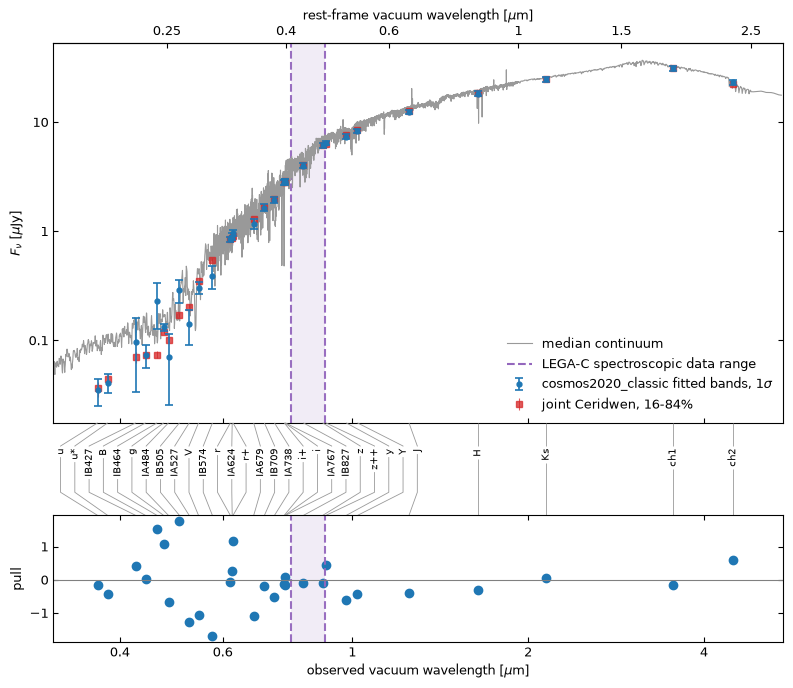

findfont: Failed to find font weight semibold, now using 700.


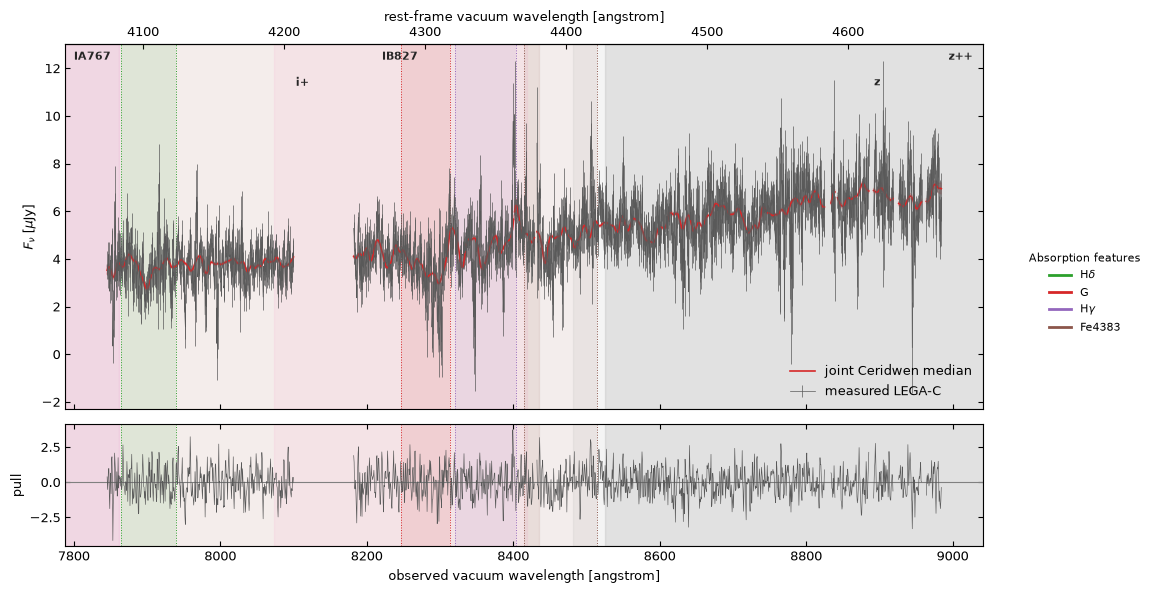

photometry chi2/datum: 0.58
spectrum chi2/bin: 1.08
joint chi2/datum: 1.07
sampled calibration floor: 9.86%


In [7]:
def posterior_batch(samples, model, count):
    total = len(next(iter(samples.values())))
    indices = np.linspace(0, total - 1, min(count, total), dtype=int)
    batch = {}
    for name, parameter_template in model.theta_init.items():
        values = np.asarray(samples[name])[indices]
        if np.shape(parameter_template) == (1,) and values.ndim == 1:
            values = values[:, None]
        batch[name] = jnp.asarray(values)
    return batch


predictive_batch = posterior_batch(joint_posterior, joint_model, 200)
predictive_warmup.join()
phot_predictions, spectrum_predictions, calibration_coefficients, calibration_vectors = predictive_draws(predictive_batch)
phot_q16, phot_q50, phot_q84 = np.percentile(phot_predictions, [16, 50, 84], axis=0)
spec_q16, spec_q50, spec_q84 = np.percentile(spectrum_predictions, [16, 50, 84], axis=0)

if PLOTS:
    median_theta = {
        name: jnp.atleast_1d(np.median(np.asarray(values), axis=0)) for name, values in joint_posterior.items()
    }
    continuum = (
        np.asarray(joint_csp.get_spectrum(joint_model.apply_transforms(median_theta)))
        * 10 ** float(median_theta["logmass"][0])
        * float(flux_factor_cgs(z_catalog, joint_csp.cosmo))
        / CGS_FNU_PER_MAGGIE
    )
    continuum_wave = np.asarray(joint_csp.wave) * (1 + z_catalog)
    continuum_mask = (continuum_wave > 2500) & (continuum_wave < 55000)

    # Photometry in microJy; the h5 stays in maggies. Band names sit on a rail between the panels.
    fitted_wave = spectrum_wave[spectrum_mask]
    plot_photometry_fit(
        FILTER_LABELS, filter_wave_eff, phot_flux / UJY_TO_MAGGIES, phot_uncertainty / UJY_TO_MAGGIES,
        phot_q16 / UJY_TO_MAGGIES, phot_q50 / UJY_TO_MAGGIES, phot_q84 / UJY_TO_MAGGIES,
        redshift=z_catalog, data_label=SETTINGS["photometry"],
        spectral_range=(fitted_wave.min(), fitted_wave.max()),
        continuum=(continuum_wave[continuum_mask], continuum[continuum_mask] / UJY_TO_MAGGIES),
        mask=phot_fit_mask,
    )
    plt.show()

calibration_fraction = float(np.exp(np.median(np.asarray(joint_posterior["log_f_calib"]))))
effective_spec_uncertainty = np.hypot(spectrum_uncertainty, calibration_fraction * np.abs(spectrum_flux if FLOOR_ON_DATA else spec_q50))
spectrum_plot_pull = np.where(
    spectrum_mask, (spectrum_flux - spec_q50) / effective_spec_uncertainty, np.nan
)

# Spectrum in microJy; the likelihood and the h5 stay in cgs F_nu.
UJY_PER_CGS = 1e29
if PLOTS:
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
    axes[0].errorbar(
        spectrum_wave,
        np.where(spectrum_mask, spectrum_flux, np.nan) * UJY_PER_CGS,
        yerr=np.where(spectrum_mask, effective_spec_uncertainty, np.nan) * UJY_PER_CGS,
        fmt="-", lw=0.5, color="0.35", label=f"measured {SURVEY_LABEL}",
    )
    axes[0].plot(
        spectrum_wave, np.where(spectrum_mask, spec_q50, np.nan) * UJY_PER_CGS, color="tab:red", lw=1.2,
        label="joint Ceridwen median",
    )
    axes[0].fill_between(
        spectrum_wave,
        np.where(spectrum_mask, spec_q16, np.nan) * UJY_PER_CGS,
        np.where(spectrum_mask, spec_q84, np.nan) * UJY_PER_CGS,
        color="tab:red", alpha=0.25,
    )
    axes[0].set(ylabel=r"$F_\nu$ [$\mu$Jy]")
    axes[0].legend(frameon=False)
    axes[1].axhline(0, color="0.5", lw=0.8)
    axes[1].plot(spectrum_wave, spectrum_plot_pull, lw=0.45, color="0.35")
    axes[1].set(xlabel="observed vacuum wavelength [angstrom]", ylabel="pull")
    mark_filter_ranges(axes[0])
    mark_filter_ranges(axes[1], show_labels=False)
    mark_absorption_features(axes[0], z_catalog, show_labels=False)
    mark_absorption_features(axes[1], z_catalog, xlabel="observed vacuum wavelength [angstrom]")
    mark_rest_wavelength_axis(axes[0], z_catalog, label="rest-frame vacuum wavelength [angstrom]")
    spectral_tight_layout()
    plt.show()

phot_chi2 = np.sum((((phot_flux - phot_q50) / phot_uncertainty) ** 2)[phot_fit_mask])
spectrum_chi2 = np.sum(
    ((spectrum_flux[spectrum_mask] - spec_q50[spectrum_mask]) / effective_spec_uncertainty[spectrum_mask]) ** 2
)
joint_chi2 = phot_chi2 + spectrum_chi2
joint_points = phot_obs.ndof + spectrum_obs.ndof
print(f"photometry chi2/datum: {phot_chi2 / phot_obs.ndof:.2f}")
print(f"spectrum chi2/bin: {spectrum_chi2 / spectrum_obs.ndof:.2f}")
print(f"joint chi2/datum: {joint_chi2 / joint_points:.2f}")
print(f"sampled calibration floor: {100 * calibration_fraction:.2f}%")

## Spectrum fit

- Every valid native pixel; grey points are pixels excluded by the masks.
- Red: posterior median and 16-84 band including the calibration polynomial.

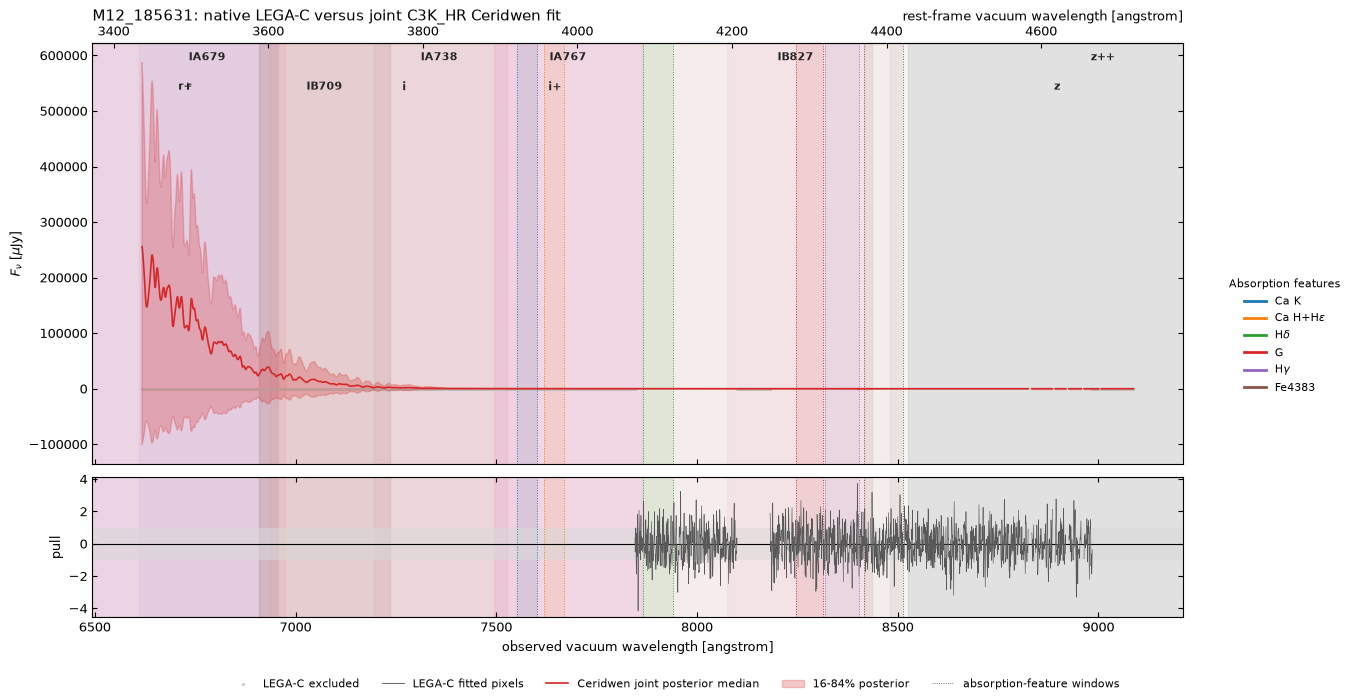

In [8]:
if PLOTS:
    native_effective_uncertainty = effective_spec_uncertainty
    native_excluded_mask = native_valid & ~spectrum_mask
    native_plot_scale = UJY_PER_CGS
    native_fitted_flux = np.where(spectrum_mask, spectrum_flux, np.nan)
    native_fitted_uncertainty = np.where(spectrum_mask, spectrum_uncertainty, np.nan)
    native_plot_pull = np.where(
        spectrum_mask, (spectrum_flux - spec_q50) / native_effective_uncertainty, np.nan
    )

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
    axes[0].scatter(
        wave_vacuum[native_excluded_mask],
        spectrum_flux[native_excluded_mask] * native_plot_scale,
        s=4, color="0.75", linewidths=0, label=f"{SURVEY_LABEL} excluded", rasterized=True,
    )
    axes[0].fill_between(
        wave_vacuum,
        (native_fitted_flux - native_fitted_uncertainty) * native_plot_scale,
        (native_fitted_flux + native_fitted_uncertainty) * native_plot_scale,
        color="0.5", alpha=0.18, linewidth=0,
    )
    axes[0].plot(
        wave_vacuum, native_fitted_flux * native_plot_scale, color="0.15", lw=0.5,
        label=f"{SURVEY_LABEL} fitted pixels", rasterized=True,
    )
    axes[0].plot(
        wave_vacuum, np.where(native_valid, spec_q50, np.nan) * native_plot_scale, color="tab:red", lw=1.2,
        label="Ceridwen joint posterior median",
    )
    axes[0].fill_between(
        wave_vacuum,
        np.where(native_valid, spec_q16, np.nan) * native_plot_scale,
        np.where(native_valid, spec_q84, np.nan) * native_plot_scale,
        color="tab:red", alpha=0.25, label="16-84% posterior",
    )
    axes[0].set(ylabel=r"$F_\nu$ [$\mu$Jy]")
    axes[0].plot([], [], color="0.3", lw=0.6, linestyle=":", label="absorption-feature windows")
    # Below the panels: inside the axes the legend covers the band names.
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", frameon=False, ncol=5, fontsize=8)
    axes[1].axhspan(-1, 1, color="0.85", alpha=0.55, linewidth=0)
    axes[1].axhline(0, color="k", lw=0.8)
    axes[1].plot(wave_vacuum, native_plot_pull, color="0.35", lw=0.45, rasterized=True)
    axes[1].set_ylabel("pull")
    mark_filter_ranges(axes[0])
    mark_filter_ranges(axes[1], show_labels=False)
    mark_absorption_features(axes[0], z_catalog, show_labels=False)
    mark_absorption_features(axes[1], z_catalog, xlabel="observed vacuum wavelength [angstrom]")
    mark_rest_wavelength_axis(
        axes[0], z_catalog, label="rest-frame vacuum wavelength [angstrom]",
        title=f"{TARGET_ID}: native {SURVEY_LABEL} versus joint C3K_HR Ceridwen fit",
    )
    spectral_tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

## Calibration polynomial

- Posterior of $P(\lambda)$: median and 16-84 band over the draws; dotted where pixels are masked.
- Full calibration is $P(\lambda)$; $a_0$ sets its constant term.

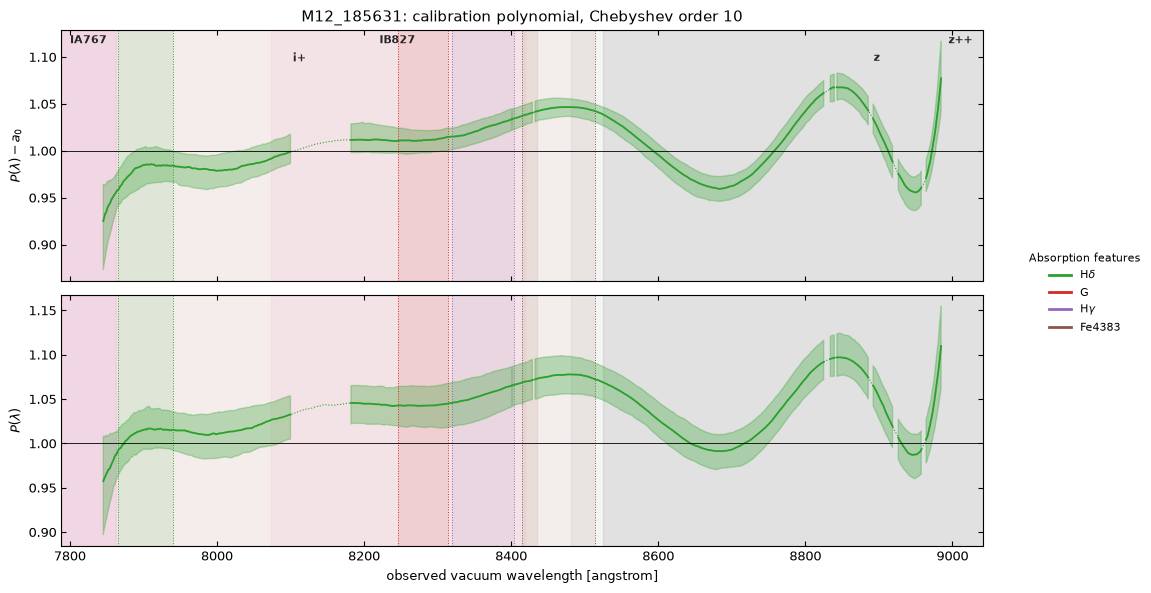

In [9]:
poly_q16, poly_q50, poly_q84 = np.percentile(calibration_vectors, [16, 50, 84], axis=0)
if PLOTS:
    fitted_range = (spectrum_wave >= spectrum_wave[spectrum_mask].min()) & (
        spectrum_wave <= spectrum_wave[spectrum_mask].max()
    )
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    shape_q16, shape_q50, shape_q84 = np.percentile(
        calibration_vectors - (calibration_coefficients[:, :1] if calibration_polynomial.fit_constant else 0.0), [16, 50, 84], axis=0
    )
scaling_draws = np.asarray(predictive_batch.get("spectrum_scaling", np.ones((len(calibration_vectors), 1)))).reshape(-1)
if PLOTS:
    full_q16, full_q50, full_q84 = np.percentile(calibration_vectors * scaling_draws[:, None], [16, 50, 84], axis=0)
    bands = [
        (shape_q16, shape_q50, shape_q84, r"$P(\lambda)-a_0$" if calibration_polynomial.fit_constant else r"$P(\lambda)$"),
        (full_q16, full_q50, full_q84, r"$s_{\mathrm{spectrum}}P(\lambda)$" if "spectrum_scaling" in joint_model.param_names else r"$P(\lambda)$"),
    ]
    for ax, (q16, q50, q84, label) in zip(axes, bands):
        ax.fill_between(
            spectrum_wave, np.where(spectrum_mask, q16, np.nan), np.where(spectrum_mask, q84, np.nan),
            color="tab:green", alpha=0.3,
        )
        ax.plot(spectrum_wave, np.where(fitted_range, q50, np.nan), color="tab:green", lw=0.8, ls=":")
        ax.plot(spectrum_wave, np.where(spectrum_mask, q50, np.nan), color="tab:green", lw=1.3)
        ax.axhline(1.0, color="k", lw=0.6)
        ax.set_ylabel(label)
    axes[0].set_title(
        f"{TARGET_ID}: calibration polynomial, Chebyshev order {SETTINGS['calibration_order']}"
    )
    mark_filter_ranges(axes[0])
    mark_filter_ranges(axes[1], show_labels=False)
    mark_absorption_features(axes[0], z_catalog, show_labels=False)
    mark_absorption_features(axes[1], z_catalog, xlabel="observed vacuum wavelength [angstrom]")
    spectral_tight_layout()
    plt.show()

## Corners and SFH

- 400 evenly spaced rows of the equal-weight posterior; [Fe/H] = logzsol on this grid.
- Formed-mass fractions per SFH bin and the mass-weighted age from the same rows.
- Physical corner; dust parameters against the mass fractions; SFH band.
- Quantile table and derived outputs to `ceridwen_derived_outputs.h5`.

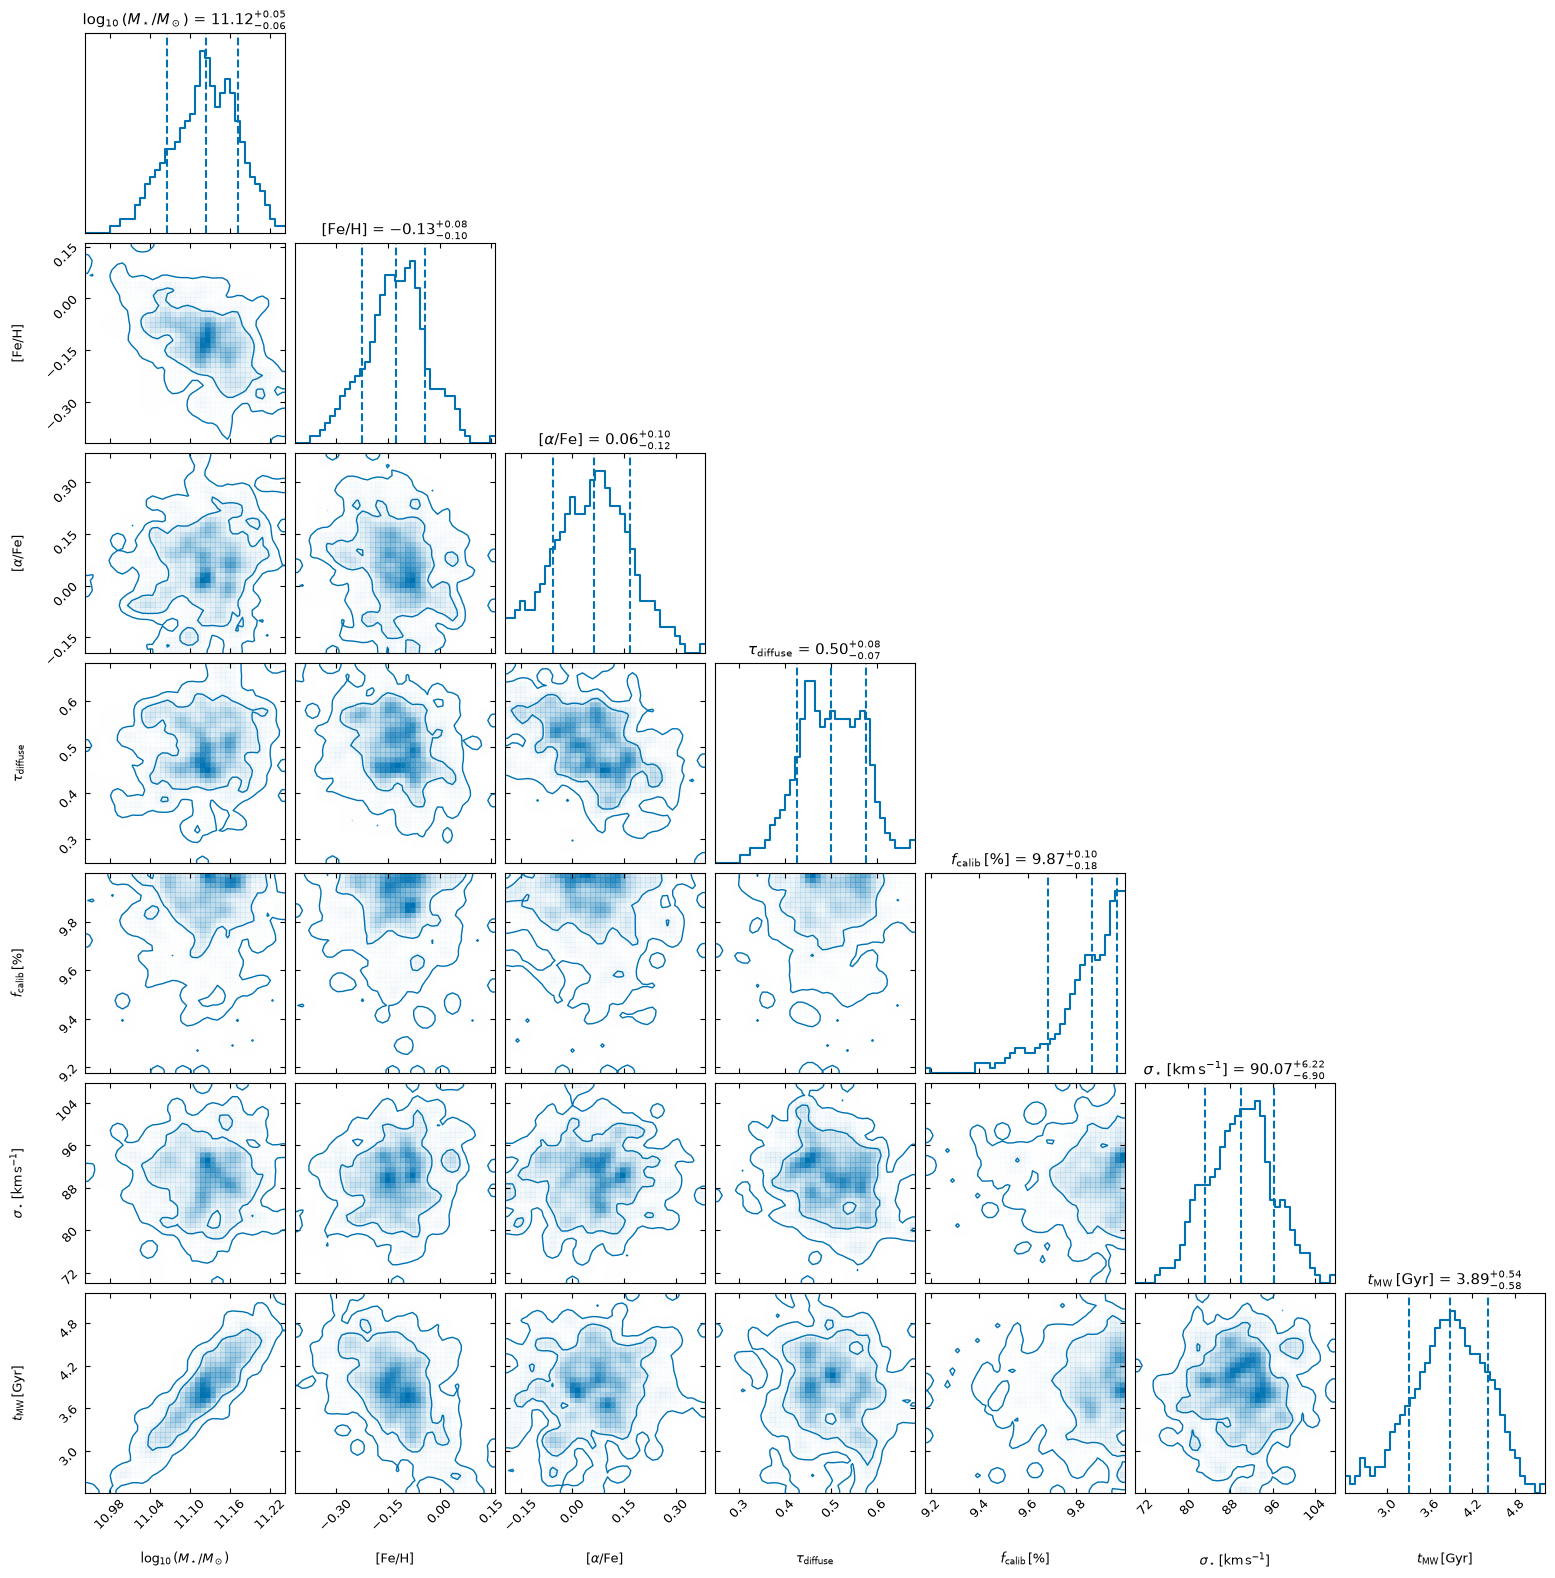

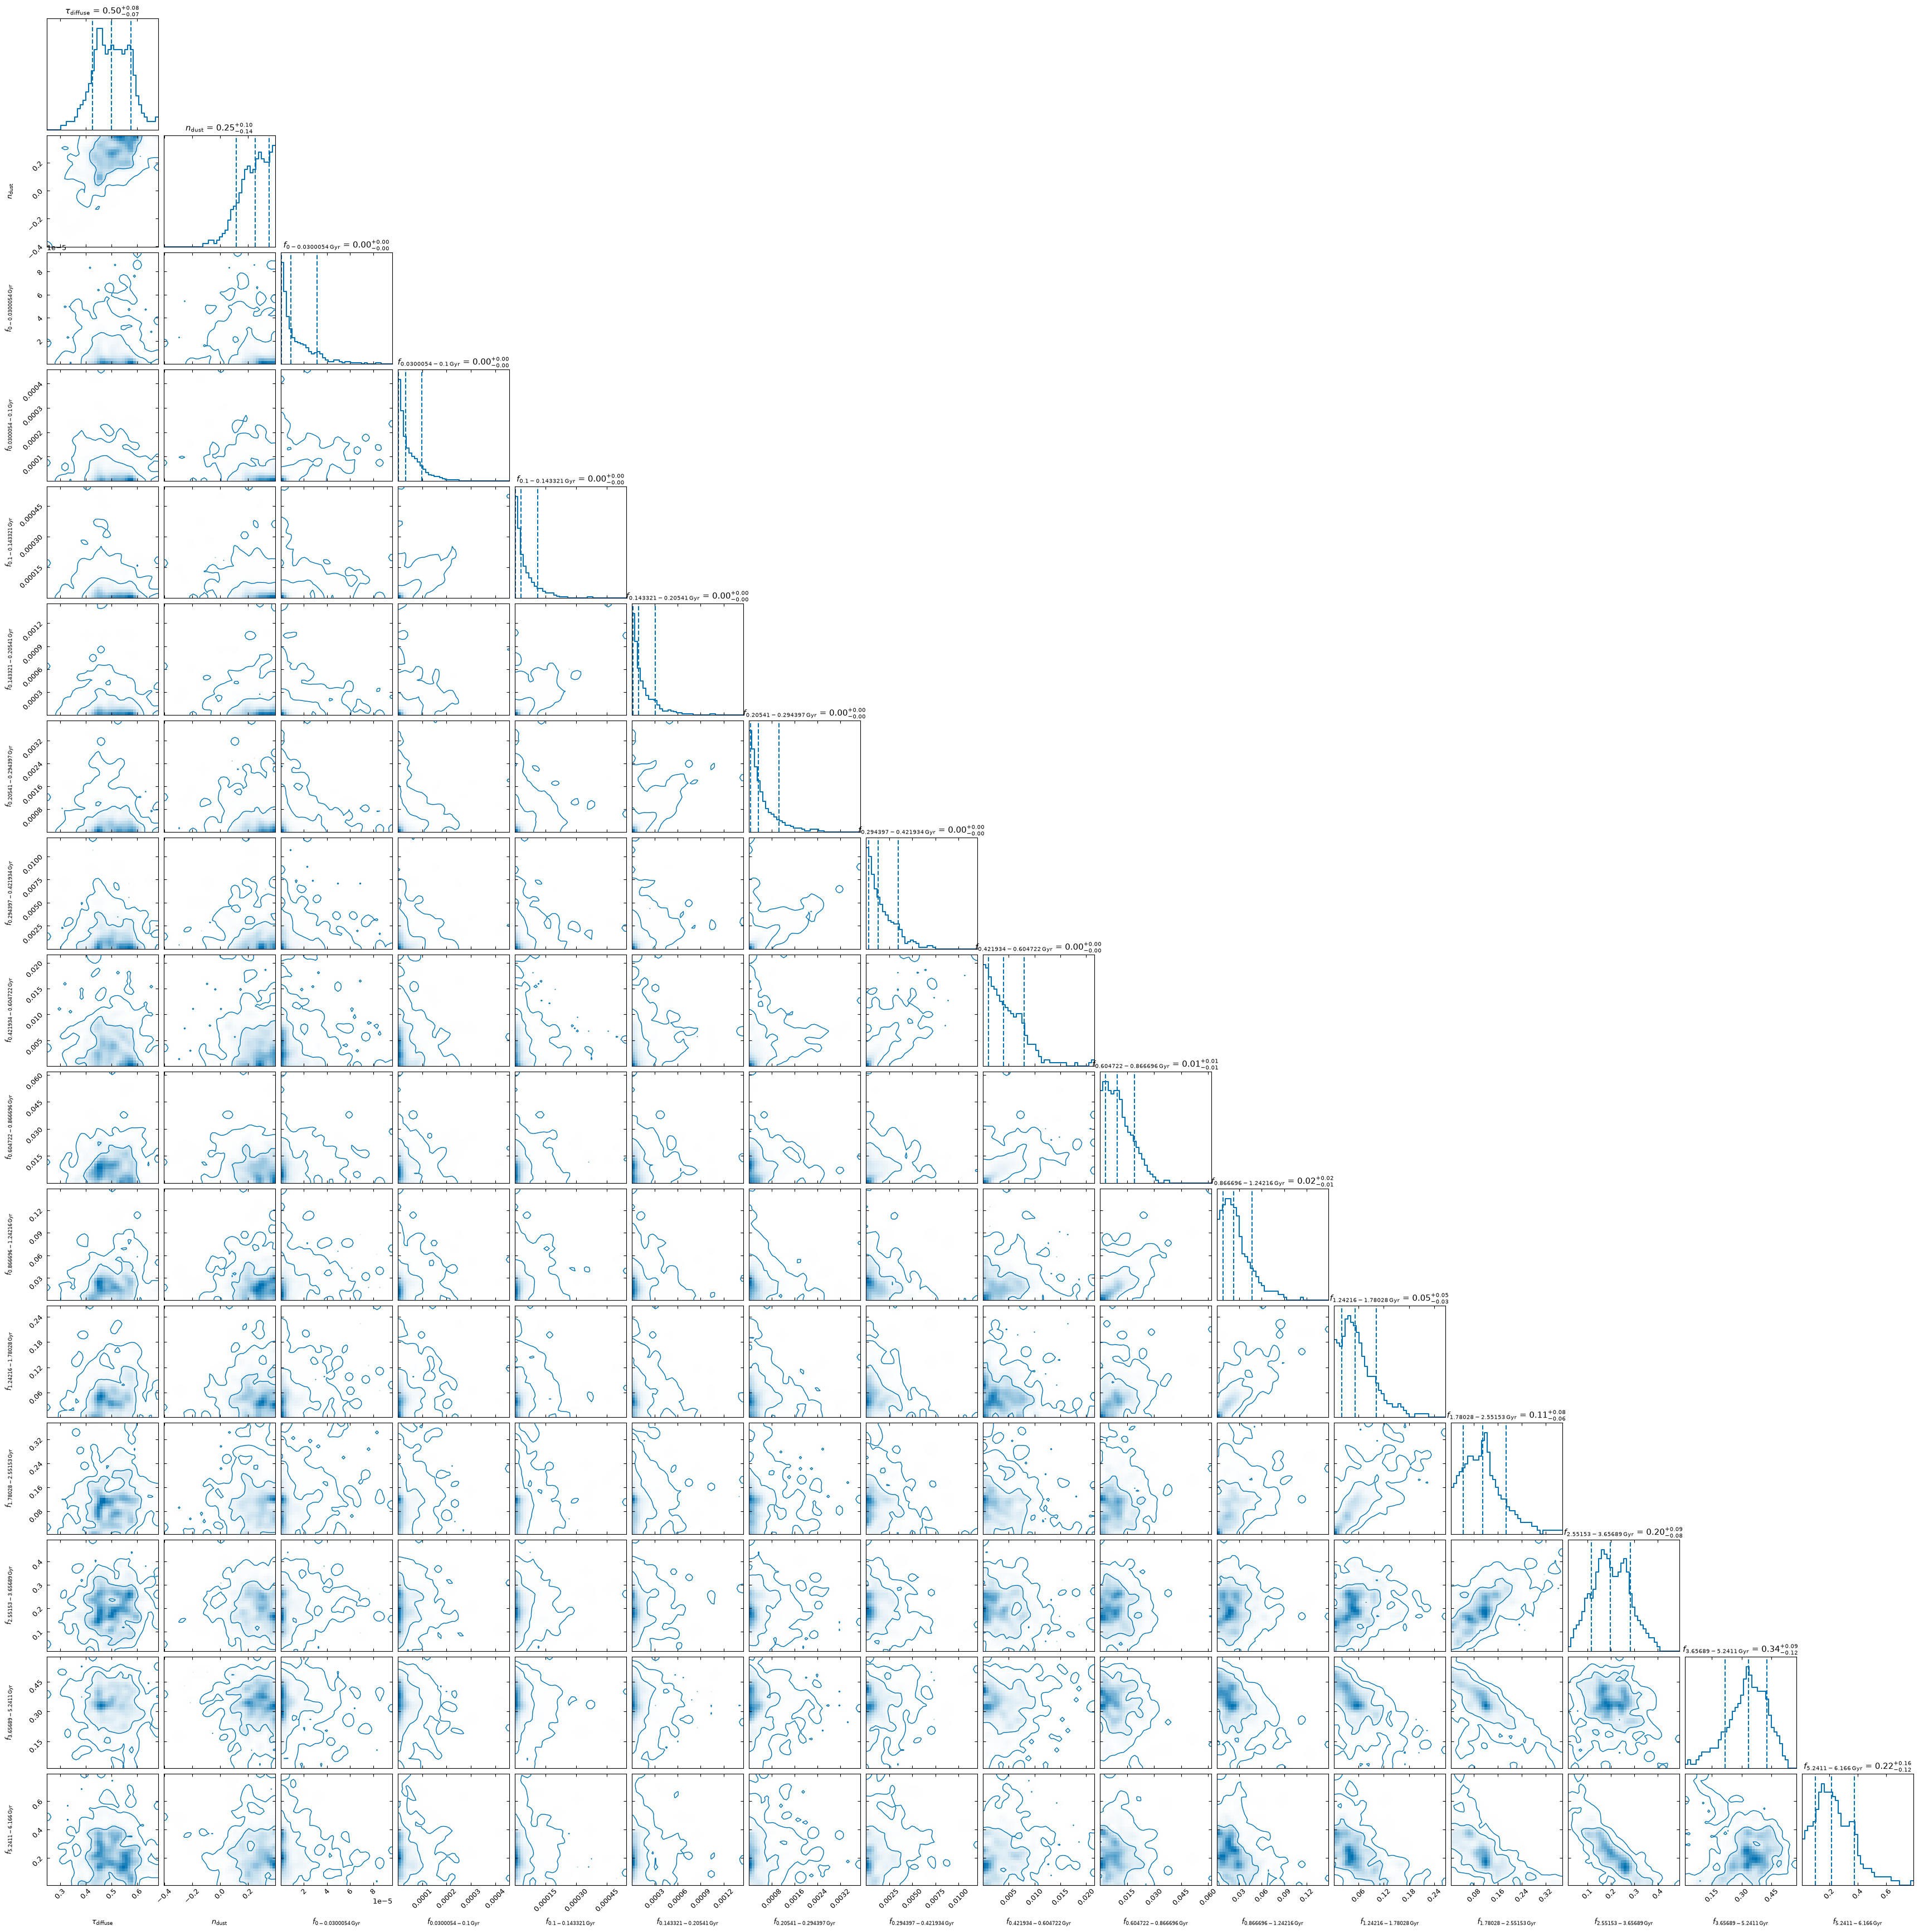

,parameter,q16,q50,q84,unit
0,logsfr_ratios[0],-0.379607,-0.054237,0.310941,dex
1,logsfr_ratios[1],-0.634042,-0.090560,0.283092,dex
2,logsfr_ratios[2],-0.676077,-0.127172,0.190303,dex
3,logsfr_ratios[3],-0.813337,-0.216888,0.153207,dex
4,logsfr_ratios[4],-1.177868,-0.237869,0.117166,dex
5,logsfr_ratios[5],-1.084480,-0.226626,0.119446,dex
6,logsfr_ratios[6],-0.684390,-0.189693,0.181165,dex
7,logsfr_ratios[7],-0.601267,-0.154739,0.195858,dex
8,logsfr_ratios[8],-0.723462,-0.195308,0.110476,dex
9,logsfr_ratios[9],-0.530456,-0.121130,0.178921,dex


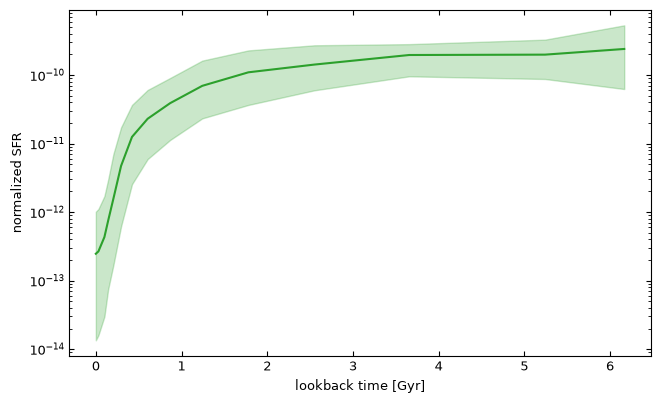

In [10]:
posterior_indices = np.linspace(0, len(joint_posterior["logmass"]) - 1, 400, dtype=int)
selected_posterior = {name: np.asarray(values)[posterior_indices] for name, values in joint_posterior.items()}


def scalar_draws(name):
    if name == "afe" and SETTINGS["fix_afe"] is not None:
        return np.full(len(posterior_indices), SETTINGS["fix_afe"])
    return np.asarray(selected_posterior[name]).reshape(len(posterior_indices))


joint_histories = np.asarray(
    [
        logsfr_ratios_to_sfh(ratios, sfh_times_yr=lookback_template * 1e9)
        for ratios in selected_posterior["logsfr_ratios"]
    ]
)
interval_masses = 0.5 * (joint_histories[:, :-1] + joint_histories[:, 1:]) * np.diff(lookback_template) * 1e9
joint_mass_fractions = interval_masses / interval_masses.sum(axis=1)[:, None]
joint_ages = (joint_mass_fractions * 0.5 * (lookback_template[:-1] + lookback_template[1:])).sum(axis=1)

calibration_percent = 100.0 * np.exp(scalar_draws("log_f_calib"))

if "zred" in PRIORS:
    # Redshift as a velocity offset from the catalogue: dv = c (z - z_cat) / (1 + z_cat).
    zred_offset_kms = C_KMS * (scalar_draws("zred") - z_catalog) / (1.0 + z_catalog)
if PLOTS:
    mass_fraction_labels = [
        rf"$f_{{{start:g}-{stop:g}\,\mathrm{{Gyr}}}}$" for start, stop in pairwise(lookback_template)
    ]
    CORNER_STYLE = {
        "bins": 40,
        "color": "#0072B2",
        "smooth": 1.2,
        "smooth1d": 1.0,
        "plot_datapoints": False,
        "plot_density": True,
        "plot_contours": True,
        "fill_contours": False,
        "hist_kwargs": {"linewidth": 1.5},
        "contour_kwargs": {"linewidths": 1.0},
        "quantiles": [0.16, 0.50, 0.84],
        "title_quantiles": [0.16, 0.50, 0.84],
        "show_titles": True,
        "levels": (0.68, 0.95),
    }

    physical = [  # (label, draws, range)
        (r"$\log_{10}(M_\star/M_\odot)$", scalar_draws("logmass"), joint_bounds["logmass"]),
        (r"$[\mathrm{Fe}/\mathrm{H}]$", scalar_draws("logzsol"), joint_bounds["logzsol"]),
        (r"$[\alpha/\mathrm{Fe}]$", scalar_draws("afe"), joint_bounds["afe"]),
        (r"$\tau_{\mathrm{diffuse}}$", scalar_draws("diffuse_tau_noll"), joint_bounds["diffuse_tau_noll"]),
        (r"$f_{\mathrm{calib}}\,[\%]$", calibration_percent, tuple(100.0 * np.exp(joint_bounds["log_f_calib"]))),
    ]
    if "spectrum_scaling" in joint_model.param_names:
        physical.append((r"$s_{\mathrm{spectrum}}$", scalar_draws("spectrum_scaling"), joint_bounds["spectrum_scaling"]))
    if "zred" in PRIORS:
        physical.append(
            (r"$\Delta v_z\,[\mathrm{km\,s^{-1}}]$", zred_offset_kms, tuple(np.percentile(zred_offset_kms, [0.1, 99.9])))
        )
    if "sigma_smooth" in PRIORS:
        physical.append(
            (r"$\sigma_\star\,[\mathrm{km\,s^{-1}}]$", scalar_draws("sigma_smooth"), joint_bounds["sigma_smooth"])
        )
    physical.append((r"$t_{\mathrm{MW}}\,[\mathrm{Gyr}]$", joint_ages, (0.0, universe_age)))
    corner.corner(
        np.column_stack([draws for _, draws, _ in physical]),
        labels=[label for label, _, _ in physical],
        range=[limits for _, _, limits in physical] if QUICK else None,
        **CORNER_STYLE,
    )
    plt.show()

    corner.corner(
        np.column_stack([scalar_draws("diffuse_tau_noll"), scalar_draws("diffuse_delta"), joint_mass_fractions]),
        labels=[r"$\tau_{\mathrm{diffuse}}$", r"$n_{\mathrm{dust}}$", *mass_fraction_labels],
        range=(
            [joint_bounds["diffuse_tau_noll"], joint_bounds["diffuse_delta"]] + [(0.0, 1.0)] * N_RATIOS
            if QUICK
            else None
        ),
        **CORNER_STYLE,
    )
    plt.show()

summary_draws = {
    **{f"logsfr_ratios[{i}]": selected_posterior["logsfr_ratios"][:, i] for i in range(N_RATIOS)},
    **{name: scalar_draws(name) for name in ["logmass", "logzsol", "afe", "diffuse_tau_noll", "log_f_calib"]},
    "calibration floor [%]": calibration_percent,
    **{f"calibration a_{n}": calibration_coefficients[:, i]
       for i, n in enumerate(range(0 if calibration_polynomial.fit_constant else 1, calibration_polynomial.order + 1))},
}
if "spectrum_scaling" in joint_model.param_names:
    summary_draws["spectrum_scaling"] = scalar_draws("spectrum_scaling")
if "zred" in PRIORS:
    summary_draws["zred"] = scalar_draws("zred")
    summary_draws["redshift offset [km/s]"] = zred_offset_kms
if "sigma_smooth" in PRIORS:
    summary_draws["sigma_smooth"] = scalar_draws("sigma_smooth")
summary_draws["mass-weighted age [Gyr]"] = joint_ages
summary_units = {
    "spectrum_scaling": "dimensionless",
    "logmass": "log10(M_sun)",
    "logzsol": "log10(Z/Z_sun) = [Fe/H] on this grid",
    "afe": "dex",
    "diffuse_tau_noll": "dimensionless",
    "log_f_calib": "natural log fraction",
    "calibration floor [%]": "percent",
    "zred": "dimensionless",
    "redshift offset [km/s]": "km/s",
    "sigma_smooth": "km/s",
    "mass-weighted age [Gyr]": "Gyr",
}
summary = pd.DataFrame(
    [
        {
            "parameter": name,
            **dict(zip(["q16", "q50", "q84"], np.percentile(draws, [16, 50, 84]))),
            "unit": "dex" if name.startswith("logsfr_ratios")
            else "dimensionless" if name.startswith("calibration a_")
            else summary_units[name],
        }
        for name, draws in summary_draws.items()
    ]
)
summary_display = summary.copy()
z_row = summary_display["parameter"] == "logzsol"
summary_display.loc[z_row, ["parameter", "unit"]] = ["[Fe/H]", "dex"]
display(summary_display)

sfh_q16, sfh_q50, sfh_q84 = np.percentile(joint_histories, [16, 50, 84], axis=0)
if PLOTS:
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.plot(lookback_template, sfh_q50, color="tab:green")
    ax.fill_between(lookback_template, sfh_q16, sfh_q84, color="tab:green", alpha=0.25)
    ax.set(yscale="log", xlabel="lookback time [Gyr]", ylabel="normalized SFR")
    plt.show()

with h5py.File(RESULT_DIR / "ceridwen_derived_outputs.h5", "w") as derived_file:
    string_dtype = h5py.string_dtype(encoding="utf-8")
    derived_file.attrs.update(
        {
            "fit_mode": "full_spectrum",
            "target_id": TARGET_ID,
            "object_id": OBJECT_ID,
            "manifest_index": MANIFEST_INDEX,
            "redshift": z_catalog,
            "sigma_star_kms": sigma_star,
            "zred_half_width": SETTINGS["zred_half_width"] if "zred" in PRIORS else 0.0,
            "sigma_star_err": sigma_star_err,
            "catalogue_sn": catalogue_sn,
            "has_4000a_coverage": has_4000a_coverage,
            "random_seed": SEED,
            "parameter_block": model_parameter_block_text,
            "photometry_source": SETTINGS["photometry"],
            "calibration_order": SETTINGS["calibration_order"],
            "calibration_fit_constant": calibration_polynomial.fit_constant,
            "calibration_prior_sigma": np.asarray(calibration_polynomial.prior_sigma),
            "wall_time_s": joint_result.wall_time_s,
            "n_likelihood_calls": joint_result.n_likelihood_calls,
            **joint_settings,
        }
    )
    summary_group = derived_file.create_group("summary")
    for column in ["parameter", "unit"]:
        summary_group.create_dataset(
            column, data=np.asarray(summary[column], dtype=object), dtype=string_dtype
        )
    for column in ["q16", "q50", "q84"]:
        summary_group.create_dataset(column, data=summary[column].to_numpy())

    sfh_group = derived_file.create_group("sfh")
    sfh_group.create_dataset("lookback_time_gyr", data=lookback_template)
    sfh_group.create_dataset("normalized_sfr_draws", data=joint_histories)
    sfh_group.create_dataset("normalized_sfr_q16", data=sfh_q16)
    sfh_group.create_dataset("normalized_sfr_q50", data=sfh_q50)
    sfh_group.create_dataset("normalized_sfr_q84", data=sfh_q84)
    sfh_group.create_dataset("mass_fraction_draws", data=joint_mass_fractions)
    for column, values in zip(["q16", "q50", "q84"], np.percentile(joint_mass_fractions, [16, 50, 84], axis=0)):
        sfh_group.create_dataset(f"mass_fraction_{column}", data=values)
    sfh_group.create_dataset("mass_weighted_age_gyr", data=joint_ages)

    diagnostics_group = derived_file.create_group("diagnostics")
    diagnostics_group.attrs.update(
        {
            "log_evidence": joint_result.log_evidence,
            "log_evidence_err": joint_result.log_evidence_err,
            "posterior_weight_ess": joint_weight_ess,
            "status": joint_status,
            "passed": joint_diagnostics_passed,
            "photometry_chi2": phot_chi2,
            "spectrum_chi2": spectrum_chi2,
            "joint_chi2": joint_chi2,
            "photometry_ndof": phot_obs.ndof,
            "spectrum_ndof": spectrum_obs.ndof,
            "joint_ndof": joint_points,
        }
    )

    photometry_group = derived_file.create_group("photometry")
    photometry_group.create_dataset("filters", data=np.asarray(FILTER_NAMES, dtype=object), dtype=string_dtype)
    photometry_group.create_dataset("wavelength", data=filter_wave_eff)
    photometry_group.create_dataset("observed", data=phot_flux)
    photometry_group.create_dataset("uncertainty", data=phot_uncertainty)
    photometry_group.create_dataset("mask", data=phot_fit_mask)
    photometry_group.create_dataset("posterior_q16", data=phot_q16)
    photometry_group.create_dataset("posterior_q50", data=phot_q50)
    photometry_group.create_dataset("posterior_q84", data=phot_q84)
    photometry_group.create_dataset("pull", data=(phot_flux - phot_q50) / phot_uncertainty)

    spectrum_group = derived_file.create_group("spectrum")
    spectrum_group.create_dataset("wavelength", data=spectrum_wave)
    spectrum_group.create_dataset("observed", data=spectrum_flux)
    spectrum_group.create_dataset("uncertainty", data=spectrum_uncertainty)
    spectrum_group.create_dataset("effective_uncertainty", data=effective_spec_uncertainty)
    spectrum_group.create_dataset("mask", data=spectrum_mask)
    spectrum_group.create_dataset("posterior_q16", data=spec_q16)
    spectrum_group.create_dataset("posterior_q50", data=spec_q50)
    spectrum_group.create_dataset("posterior_q84", data=spec_q84)
    spectrum_group.create_dataset("pull", data=spectrum_plot_pull)

    calibration_group = derived_file.create_group("calibration")
    calibration_group.attrs.update(
        {
            "order": SETTINGS["calibration_order"],
            "fit_constant": calibration_polynomial.fit_constant,
            "prior_sigma": np.asarray(calibration_polynomial.prior_sigma),
            "marginalized": True,
            "basis": "P(x) = 1 + sum_n a_n T_n(x), Chebyshev, x in [-1, 1] over fitted pixels",
        }
    )
    calibration_group.create_dataset("x", data=np.asarray(calibration_polynomial.x))
    calibration_group.create_dataset("coefficient_draws", data=calibration_coefficients)
    if "spectrum_scaling" in joint_model.param_names:
        calibration_group.create_dataset("spectrum_scaling_draws", data=scaling_draws)
    calibration_group.create_dataset("coefficient_degrees", data=np.arange(0 if calibration_polynomial.fit_constant else 1, calibration_polynomial.order + 1))
    calibration_group.create_dataset("polynomial_q16", data=poly_q16)
    calibration_group.create_dataset("polynomial_q50", data=poly_q50)
    calibration_group.create_dataset("polynomial_q84", data=poly_q84)

## Prior-to-posterior KL

- Per-parameter $D_{\mathrm{KL}}(\mathrm{posterior}\,\|\,\mathrm{prior})$ in bits from the stored dead points.
- `kl_table` maps each draw through its own prior; error bars are a bootstrap.
- SFH bins: $\log_{10}$ SFR per bin, prior from prior draws through `sfh_from_ratios`; own noise floor.
- Points sorted from most to least constrained, log axis.
- Grey band: measured estimator noise floor, 95th percentile of 200 prior-only draws with the real weights.
- Dashed line at 1 bit: a factor-two narrowing of the prior. Stated convention, not a standard.


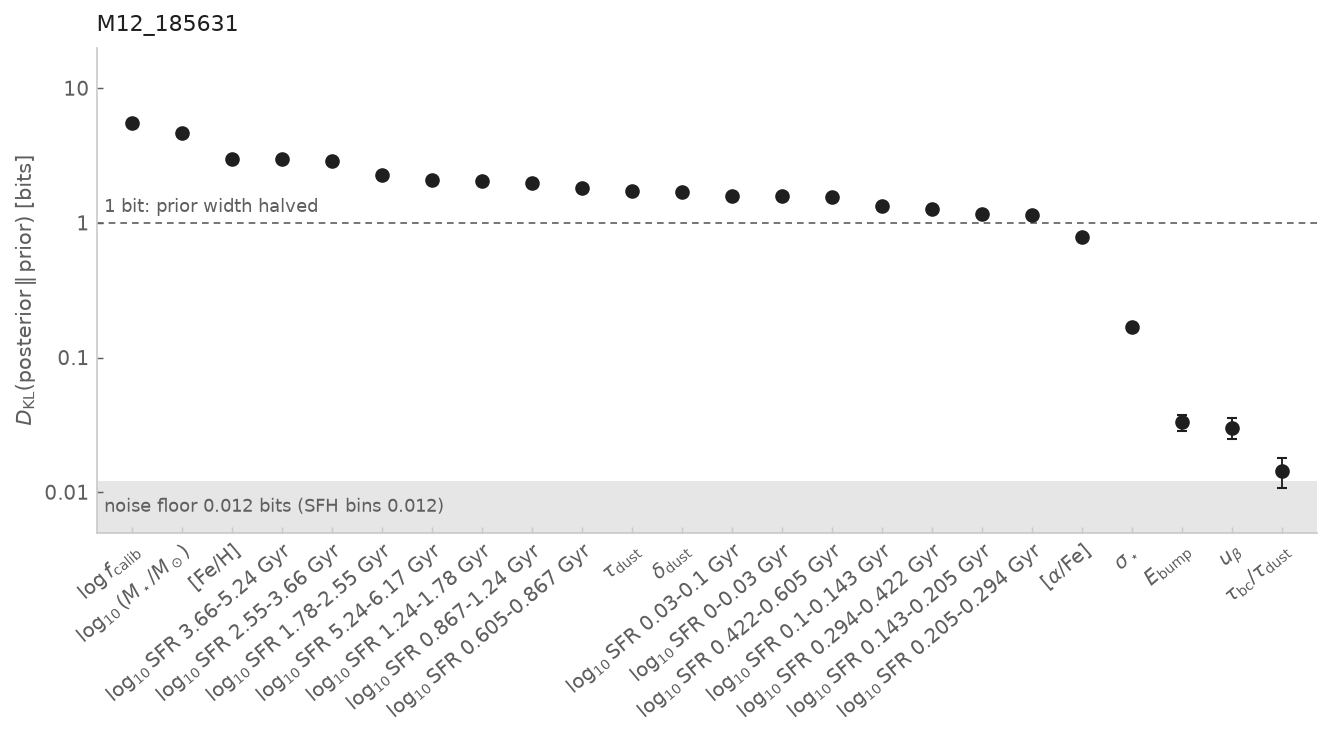

In [11]:
if PLOTS:
    from plot_prior_kl import kl_table, log_sfr_noise_floor  # noqa: E402
    from per_galaxy_diagnostics import load_galaxy, marginal_kl_bits, posterior_weights  # noqa: E402
    import matplotlib.ticker as mt  # noqa: E402

    kl_galaxy = load_galaxy(RESULT_DIR)
    kl_bits = kl_table(kl_galaxy).sort_values("bits", ascending=False)
    kl_w = posterior_weights(kl_galaxy)
    kl_rng = np.random.default_rng(SEED)
    kl_floor = np.percentile([marginal_kl_bits(kl_rng.uniform(0, 1, len(kl_w)), kl_w) for _ in range(200)], 95)
    kl_floor_sfr = log_sfr_noise_floor(kl_galaxy, seed=SEED)  # SFH bins: prior is a finite sample, so its own floor
    kl_floor = max(kl_floor, kl_floor_sfr)
    kl_x = np.arange(len(kl_bits))
    kl_x0, kl_x1, kl_ymin, kl_ymax = -0.7, len(kl_bits) - 0.3, 0.005, 20
    ink, ink_soft, rule, wash = "#1F1F1F", "#5F5F5F", "#C9C9C9", "#E6E6E6"
    fig, ax = plt.subplots(figsize=(10.5, 4.2), dpi=150)
    ax.set_yscale("log")
    ax.axhspan(kl_ymin, kl_floor, color=wash, lw=0, zorder=1)
    ax.axhline(1, color=ink_soft, lw=0.8, ls=(0, (4, 3)), zorder=2)
    ax.errorbar(kl_x, kl_bits["bits"], yerr=kl_bits["err"], fmt="o", ms=6, color=ink, ecolor=ink, elinewidth=0.9, capsize=2.5, zorder=3)
    ax.text(kl_x0 + 0.15, 1.12, "1 bit: prior width halved", fontsize=8.5, color=ink_soft, ha="left", va="bottom")
    ax.text(kl_x0 + 0.15, np.sqrt(kl_ymin * kl_floor), f"noise floor {kl_floor:.3f} bits (SFH bins {kl_floor_sfr:.3f})", fontsize=8.5, color=ink_soft, ha="left", va="center")
    ax.set_xticks(kl_x)
    ax.set_xticklabels(kl_bits["label"], rotation=40, ha="right", rotation_mode="anchor", fontsize=9.5, color=ink_soft)
    ax.set_xlim(kl_x0, kl_x1)
    ax.set_ylim(kl_ymin, kl_ymax)
    ax.yaxis.set_major_locator(mt.FixedLocator([0.01, 0.1, 1, 10]))
    ax.yaxis.set_major_formatter(mt.FixedFormatter(["0.01", "0.1", "1", "10"]))
    ax.yaxis.set_minor_locator(mt.NullLocator())
    ax.set_ylabel(r"$D_{\mathrm{KL}}(\mathrm{posterior}\,\|\,\mathrm{prior})$ [bits]", fontsize=10, color=ink_soft)
    ax.tick_params(axis="y", labelsize=9.5, colors=ink_soft, length=3, width=0.7, right=False)
    ax.tick_params(axis="x", length=3, width=0.7, color=rule, pad=4, top=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(rule)
    ax.set_title(TARGET_ID, loc="left", fontsize=10.5, color=ink, pad=8)
    plt.show()
